# 🧬 GlucoProfile — Clustering non supervisé des profils patients

## Objectif
Ce notebook constitue la deuxième étape du projet GlucoProfile.

À partir du dataset nettoyé (notebook `01_cleaning`), nous allons :

1. comprendre le fonctionnement de plusieurs algorithmes de clustering ;
2. justifier le choix des modèles comparés ;
3. comparer plusieurs scalers et choisir le meilleur pour chaque modèle ;
4. déterminer le nombre optimal de clusters pour chaque modèle ;
5. évaluer la qualité **et la stabilité** de chaque clustering ;
6. choisir le modèle final ;
7. ajouter la colonne `Cluster` au dataset ;
8. sauvegarder les artefacts (scaler, modèle) pour MLflow et la classification.

> **Rappel important :** aucune variable `Outcome` n'est utilisée. Les profils sont découverts de façon **non supervisée**.

## Deux représentations des données
| Dataset | Contenu | Usage |
|---|---|---|
| `df_transformed` | Insulin (log1p), DPF (sqrt), Age (log1p) | Entrée des algorithmes de clustering |
| `df_clean` | Unités cliniques d'origine | Interprétation des clusters et seuils de risque |

Les deux datasets ont exactement les mêmes lignes dans le même ordre.

## 1. Importation des bibliothèques

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.preprocessing import (
    StandardScaler,
    RobustScaler,
    MinMaxScaler,
    MaxAbsScaler,
    QuantileTransformer,
    PowerTransformer,
)
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
)
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.datasets import make_blobs, make_moons

import joblib

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

## 2. Configuration du projet

Nous centralisons les chemins et les constantes pour garantir la reproductibilité.

- `RANDOM_STATE` : graine aléatoire fixe, pour retrouver les mêmes résultats à chaque exécution.
- `K_RANGE` : valeurs de *k* (nombre de clusters) testées, de 2 à 8. Au-delà, les groupes deviennent trop petits pour être interprétables cliniquement.

In [2]:
PROJECT_ROOT = Path.cwd().resolve().parent

CLEANED_DATA_PATH = PROJECT_ROOT / "data" / "processed" / "diabetes_cleaned.csv"
TRANSFORMED_DATA_PATH = PROJECT_ROOT / "data" / "processed" / "diabetes_transformed.csv"

REPORTS_DIR = PROJECT_ROOT / "reports"
MODELS_DIR = PROJECT_ROOT / "models"

REPORTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
K_RANGE = range(2, 9)

FEATURES = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
]

print("Project root :", PROJECT_ROOT)
print("Cleaned data :", CLEANED_DATA_PATH)
print("Transformed  :", TRANSFORMED_DATA_PATH)

Project root : /home/badr-eddine-slaoui/Documents/GlucoProfile
Cleaned data : /home/badr-eddine-slaoui/Documents/GlucoProfile/data/processed/diabetes_cleaned.csv
Transformed  : /home/badr-eddine-slaoui/Documents/GlucoProfile/data/processed/diabetes_transformed.csv


## 3. Chargement et vérification des données

Nous chargeons les deux représentations et vérifions leur cohérence :

- mêmes dimensions et mêmes colonnes ;
- aucune valeur manquante ou infinie ;
- même ordre des lignes (indispensable pour relier un cluster à un patient en unités cliniques).

In [3]:
df_clean = pd.read_csv(CLEANED_DATA_PATH)
df_transformed = pd.read_csv(TRANSFORMED_DATA_PATH)

X_model = df_transformed[FEATURES].copy()

assert df_clean.shape == df_transformed.shape
assert list(df_clean.columns) == FEATURES
assert list(df_transformed.columns) == FEATURES
assert X_model.isna().sum().sum() == 0
assert np.isfinite(X_model.to_numpy()).all()

print(f"df_clean       : {df_clean.shape}")
print(f"df_transformed : {df_transformed.shape}")
print("✅ Données valides et cohérentes.")

display(X_model.head())

df_clean       : (768, 8)
df_transformed : (768, 8)
✅ Données valides et cohérentes.


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6.0,148.0,72.0,35.00000,5.393277,33.6,0.791833,3.931826
1,1.0,85.0,66.0,29.00000,4.266938,26.6,0.592453,3.465736
2,8.0,183.0,64.0,21.53261,5.596577,23.3,0.819756,3.496508
3,1.0,89.0,66.0,23.00000,4.553877,28.1,0.408656,3.091042
4,0.0,137.0,40.0,35.00000,5.129899,43.1,1.512614,3.526361


## 4. Comment fonctionnent les algorithmes de clustering ?

Le **clustering** consiste à regrouper des observations *similaires* sans connaître à l'avance les groupes. L'algorithme ne reçoit aucune étiquette : il cherche seulement une structure dans les données.

Pour expliquer chaque modèle, nous utilisons le même mini-exemple : **6 patients décrits uniquement par leur glycémie** (une seule dimension, pour rester simple).

| Patient | A | B | C | D | E | F |
|---|---|---|---|---|---|---|
| Glucose | 90 | 95 | 100 | 180 | 185 | 190 |

On voit à l'œil nu deux groupes : un groupe « glycémie normale » (A, B, C) et un groupe « glycémie élevée » (D, E, F).

---

### 4.1 K-Means (partitionnement par centroïdes)

**Idée :** chaque cluster est représenté par un point central (le *centroïde*). Chaque patient appartient au centroïde le plus proche.

**Algorithme (k = 2) :**
1. On place 2 centroïdes au hasard, par exemple sur 90 et 190.
2. **Affectation :** chaque patient va vers le centroïde le plus proche.
   A, B, C → centroïde 90 ; D, E, F → centroïde 190.
3. **Mise à jour :** chaque centroïde devient la moyenne de son groupe.
   Nouveau centroïde 1 = (90+95+100)/3 = **95** ; nouveau centroïde 2 = (180+185+190)/3 = **185**.
4. On répète les étapes 2 et 3 jusqu'à ce que plus rien ne change. Ici l'algorithme converge dès la 2ᵉ itération.

**Inertie finale :** somme des carrés des distances aux centroïdes = (25+0+25) + (25+0+25) = **100**.

| ✅ Avantages | ⚠️ Limites |
|---|---|
| Rapide, simple, très utilisé | Il faut choisir *k* à l'avance |
| Fournit des centroïdes interprétables | Suppose des groupes plutôt sphériques et de taille similaire |
| Peut prédire le cluster d'un nouveau patient | Sensible aux outliers et à l'échelle des variables |

---

### 4.2 Gaussian Mixture Model — GMM (clustering probabiliste)

**Idée :** on suppose que les données viennent d'un mélange de *k* lois normales (courbes en cloche). Chaque cluster est une cloche avec sa propre moyenne et sa propre forme (étirée, inclinée…).

**Différence clé avec K-Means : l'affectation est « douce »**. Chaque patient reçoit une **probabilité** d'appartenir à chaque cluster.

**Sur notre exemple :**
- Patient A (90) : 99,9 % groupe 1, 0,1 % groupe 2.
- Un 7ᵉ patient à 140, exactement au milieu des deux centres (95 et 185) : **50 % / 50 %**. K-Means l'enverrait arbitrairement d'un côté, le GMM exprime son incertitude.

**Algorithme EM (Expectation-Maximization) :**
1. *E-step :* calculer la probabilité d'appartenance de chaque patient à chaque cloche.
2. *M-step :* réajuster moyenne, forme et poids de chaque cloche selon ces probabilités.
3. Répéter jusqu'à stabilisation.

| ✅ Avantages | ⚠️ Limites |
|---|---|
| Clusters de formes elliptiques | Suppose des données proches de lois normales |
| Probabilités d'appartenance (utile en médecine) | Plus de paramètres, plus lent |
| Choix de *k* par critères statistiques (BIC, AIC) | Sensible à l'initialisation |

---

### 4.3 Clustering hiérarchique agglomératif

**Idée :** on part de chaque patient seul, puis on **fusionne progressivement** les groupes les plus proches, jusqu'à n'en avoir plus qu'un. Le résultat est un arbre (*dendrogramme*) que l'on « coupe » à la hauteur voulue.

**Sur notre exemple :**
1. Au départ : {A} {B} {C} {D} {E} {F}.
2. Fusion des plus proches (distance 5) : {A,B} puis {B,C} → {A,B,C} ; de même {D,E,F}.
3. Il reste 2 groupes dont la distance (≈ 90) est **bien plus grande** que les fusions précédentes (5 à 10).
4. Ce grand saut indique qu'il faut **couper à 2 clusters**.

**Critère de fusion « Ward » :** à chaque étape, on fusionne les deux groupes dont l'union **augmente le moins** la variance interne. C'est le critère le plus proche de K-Means.

| ✅ Avantages | ⚠️ Limites |
|---|---|
| Dendrogramme : vision de toute la hiérarchie | Pas de méthode `predict` pour un nouveau patient |
| Pas d'initialisation aléatoire (résultat déterministe) | Coût mémoire élevé sur de gros datasets (ici : 768 lignes, sans problème) |
| Une fusion faite n'est jamais remise en cause | |

---

### 4.4 DBSCAN (clustering par densité)

**Idée :** un cluster est une zone **dense** de points, séparée d'autres zones denses par des zones vides. Les points isolés sont déclarés **bruit** (outliers).

**Deux paramètres :**
- `eps` : rayon du voisinage autour d'un point ;
- `min_samples` : nombre minimal de voisins (soi-même inclus) pour qu'un point soit « central ».

**Sur notre exemple (eps = 10, min_samples = 3) :**
- Patient B (95) : voisins dans un rayon de 10 → A, B, C = 3 voisins → point **central**.
- A, B, C forment un groupe dense ; D, E, F forment un autre groupe dense → **2 clusters**.
- Un patient isolé à 140 n'a aucun voisin dans un rayon de 10 → **bruit** (étiquette -1).

| ✅ Avantages | ⚠️ Limites |
|---|---|
| Ne demande pas *k* | Très sensible au choix de `eps` |
| Trouve des formes quelconques (croissants, anneaux…) | Difficile quand les densités varient |
| Détecte les outliers automatiquement | Se dégrade en dimension élevée ; pas de `predict` |

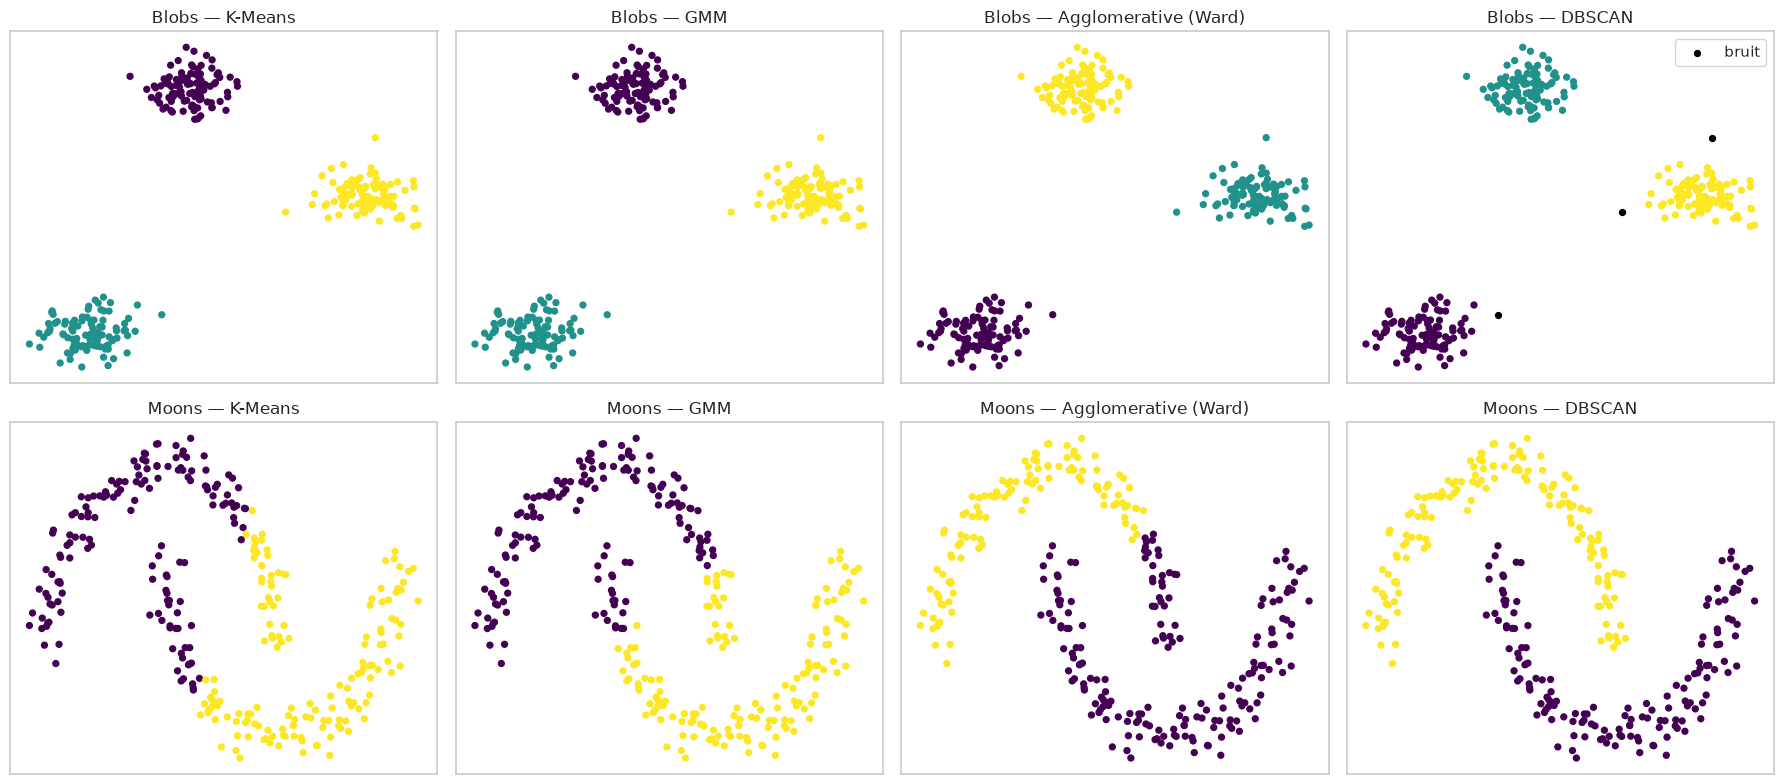

In [4]:
toy_data = {
    "Blobs": make_blobs(n_samples=300, centers=3, cluster_std=1.0, random_state=RANDOM_STATE)[0],
    "Moons": make_moons(n_samples=300, noise=0.07, random_state=RANDOM_STATE)[0],
}

toy_params = {
    "Blobs": {"k": 3, "eps": 1.2},
    "Moons": {"k": 2, "eps": 0.2},
}

def toy_models(k, eps):
    return {
        "K-Means": KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE),
        "GMM": GaussianMixture(n_components=k, random_state=RANDOM_STATE),
        "Agglomerative (Ward)": AgglomerativeClustering(n_clusters=k, linkage="ward"),
        "DBSCAN": DBSCAN(eps=eps, min_samples=5),
    }

fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for row, (dataset_name, X_toy) in enumerate(toy_data.items()):
    params = toy_params[dataset_name]
    for col, (model_name, model) in enumerate(toy_models(params["k"], params["eps"]).items()):
        labels = model.fit_predict(X_toy)
        ax = axes[row, col]
        noise = labels == -1
        ax.scatter(X_toy[~noise, 0], X_toy[~noise, 1], c=labels[~noise], cmap="viridis", s=18)
        if noise.any():
            ax.scatter(X_toy[noise, 0], X_toy[noise, 1], c="black", s=18, label="bruit")
            ax.legend()
        ax.set_title(f"{dataset_name} — {model_name}")
        ax.set_xticks([])
        ax.set_yticks([])

plt.tight_layout()
plt.show()

## 6. Pourquoi ces quatre modèles ?

Nous ne comparons pas des algorithmes au hasard : chacun représente une **famille** de méthodes avec une hypothèse différente sur la forme des groupes.

| Modèle | Famille | Hypothèse sur les groupes | Pourquoi le tester ici |
|---|---|---|---|
| **K-Means** | Centroïdes | Groupes compacts et sphériques | Imposé par le projet ; référence du domaine ; fournit des moyennes par cluster pour appliquer les seuils de risque |
| **GMM** | Probabiliste | Groupes elliptiques de tailles variées | Les variables cliniques sont corrélées (Glucose–Insulin, SkinThickness–BMI) : des clusters elliptiques peuvent mieux les décrire. Les probabilités sont utiles en médecine |
| **Agglomératif (Ward)** | Hiérarchique | Aucune forme imposée, fusion par variance minimale | Résultat déterministe ; le dendrogramme donne une validation visuelle indépendante du choix de *k* |
| **DBSCAN** | Densité | Zones denses séparées par du vide | Teste s'il existe une vraie séparation naturelle en groupes, et détecte les profils réellement atypiques |

### Modèles écartés
| Modèle | Raison |
|---|---|
| Spectral Clustering | Coûteux, réglages nombreux, gain peu probable sur 768 lignes et 8 variables |
| Mean Shift | Dépend d'une largeur de bande difficile à régler, sans avantage clair ici |
| OPTICS | Variante de DBSCAN, redondante |
| BIRCH / Bisecting K-Means | Variantes ou approximations de K-Means, pensées pour de très grands volumes |

### Point d'attention pour la suite du projet
Seuls K-Means et GMM possèdent une méthode `predict`. Ce n'est pas bloquant : l'étape 5 du projet entraîne un **classifieur supervisé** sur la colonne `Cluster`, et c'est ce classifieur qui prédira le risque des nouveaux patients.

## 7. Les scalers : pourquoi et lesquels comparer ?

### Pourquoi mettre à l'échelle ?
Les algorithmes de clustering reposent sur des **distances**. Si une variable a des valeurs beaucoup plus grandes que les autres, elle domine le calcul.

> Exemple : deux patients diffèrent de 50 en Glucose (ex. 100 vs 150) et de 0,5 en DiabetesPedigreeFunction. Sans mise à l'échelle, la distance est ≈ 50 : la différence de DPF est invisible, alors qu'elle peut être cliniquement importante.

Un scaler remet toutes les variables à des échelles comparables.

### Mini-exemple commun
Variable avec 4 valeurs : **10, 20, 30, 100** (100 est un outlier). Médiane = 25, Q1 = 17,5, Q3 = 47,5 (IQR = 30), moyenne = 40, écart-type ≈ 35,4.

| Scaler | Formule | Comment ça marche | 10 → 20 → 30 → 100 | Sensible aux outliers ? |
|---|---|---|---|---|
| **Aucun** | x | Les données restent telles quelles | 10, 20, 30, 100 | — |
| **StandardScaler** | (x − moyenne) / écart-type | Centre sur 0, écart-type 1 | -0,85 · -0,57 · -0,28 · 1,70 | Oui (moyenne et écart-type sont tirés par l'outlier) |
| **RobustScaler** | (x − médiane) / IQR | Centre sur la médiane, divise par l'écart interquartile | -0,50 · -0,17 · 0,17 · 2,50 | Non |
| **MinMaxScaler** | (x − min) / (max − min) | Ramène dans [0, 1] | 0 · 0,11 · 0,22 · 1 | Très (l'outlier écrase les 3 autres valeurs) |
| **MaxAbsScaler** | x / \|max\| | Divise par la plus grande valeur absolue | 0,1 · 0,2 · 0,3 · 1 | Très |
| **QuantileTransformer (uniform)** | rang du point | Remplace chaque valeur par son rang → distribution uniforme | 0 · 0,33 · 0,67 · 1 | Non (l'outlier devient simplement « le plus grand ») |
| **QuantileTransformer (normal)** | rang puis loi normale | Même principe, avec une sortie en cloche | valeurs en cloche | Non |
| **PowerTransformer (Yeo-Johnson)** | transformation puissance | Cherche la transformation qui rend la distribution la plus gaussienne possible | — | Réduit l'asymétrie |

### Pourquoi ces scalers ?
- **StandardScaler** et **RobustScaler** : les références, avec des comportements opposés face aux outliers.
- **MinMaxScaler** et **MaxAbsScaler** : les alternatives classiques ; nous attendons qu'elles soient moins bonnes à cause des outliers conservés, mais nous le vérifions.
- **QuantileTransformer** et **PowerTransformer** : des scalers « non linéaires » qui modifient la forme de la distribution, pas seulement l'échelle.
- **Aucun scaler** : sert de point de comparaison (preuve que le scaling est utile).

### Scaler exclu : `Normalizer`
Le `Normalizer` met à l'échelle **chaque ligne** (chaque patient) pour que son vecteur ait une longueur de 1, au lieu de traiter chaque colonne. Cela effacerait l'« intensité » globale du profil d'un patient (un patient à glycémie très élevée serait confondu avec un patient à glycémie modérée de même forme), ce qui est inadapté ici.

> Les scalers sont comparés **pour chaque modèle séparément** : le meilleur scaler pour K-Means n'est pas forcément le meilleur pour GMM ou pour un clustering hiérarchique.

## 8. Les métriques d'évaluation du clustering

En clustering non supervisé, il n'y a pas de « bonne réponse » à comparer. On évalue donc la **qualité de la structure** trouvée avec plusieurs métriques internes, puis on mesure la **stabilité**.

---

### Inertie (WCSS : Within-Cluster Sum of Squares)
- **C'est quoi ?** La somme des carrés des distances entre chaque point et le centroïde de son cluster.
- **Comment ça marche ?** Dans l'exemple K-Means précédent : (25+0+25)+(25+0+25) = 100.
- **À quoi ça sert ?** Mesure la compacité. Plus elle est **faible**, plus les clusters sont compacts.
- **Piège :** elle diminue toujours quand *k* augmente (avec *k* = nombre de points, elle vaut 0). On cherche donc le **coude** de la courbe : le point où l'ajout d'un cluster ne fait presque plus baisser l'inertie.

### Score de silhouette (entre -1 et 1, plus c'est **haut**, mieux c'est)
- **C'est quoi ?** Pour chaque point, on mesure s'il est bien placé dans son cluster.
- **Comment ça marche ?** Pour un point :
  - *a* = distance moyenne aux autres points de **son** cluster ;
  - *b* = distance moyenne aux points du **cluster voisin le plus proche** ;
  - silhouette = (b − a) / max(a, b).
- **Exemple :** a = 2, b = 6 → (6−2)/6 = **0,67** (point bien placé). Si a = b → 0 (point à la frontière). Si a > b → négatif (probablement dans le mauvais cluster).
- **Lecture indicative :** > 0,5 structure nette ; 0,25–0,5 structure moyenne ; < 0,25 structure faible. Les données cliniques réelles dépassent rarement 0,4.

### Indice de Davies-Bouldin (≥ 0, plus c'est **bas**, mieux c'est)
- **C'est quoi ?** Mesure la ressemblance moyenne entre chaque cluster et son cluster le plus similaire.
- **Comment ça marche ?** Pour deux clusters : (dispersion de l'un + dispersion de l'autre) / distance entre leurs centres. On garde le pire voisin de chaque cluster, puis on fait la moyenne.
- **Exemple :** deux clusters de dispersion 1 chacun, centres à 10 → (1+1)/10 = 0,2 (très bien séparés). Centres à 2 → 1,0 (se chevauchent).

### Indice de Calinski-Harabasz (plus c'est **haut**, mieux c'est)
- **C'est quoi ?** Rapport entre la dispersion **entre** les clusters et la dispersion **à l'intérieur** des clusters.
- **Comment ça marche ?** Si les centres des clusters sont éloignés les uns des autres et que les points sont proches de leur centre, le rapport est grand.
- **Attention :** il favorise souvent K-Means et les clusters sphériques, et ses valeurs ne sont pas comparables entre scalers différents.

### Taille des clusters (% min et % max)
- **À quoi ça sert ?** Détecter les clusters minuscules (par exemple 2 % des patients), qui sont rarement exploitables cliniquement, et les partitions très déséquilibrées.

### Stabilité (ARI : Adjusted Rand Index)
- **C'est quoi ?** L'ARI compare deux partitions de **mêmes** patients. Il vaut **1** si elles sont identiques (même si les numéros de clusters sont permutés), **≈ 0** si elles sont comparables au hasard.
- **Comment on l'utilise ici ?** On tire deux sous-échantillons aléatoires de 80 % des patients, on lance le clustering sur chacun, puis on compare les affectations des patients présents dans les deux. On répète 10 fois et on prend la moyenne.
- **Exemple :** ARI moyen de 0,95 = les groupes se retrouvent presque toujours ; 0,50 = les groupes changent beaucoup selon l'échantillon, le clustering n'est pas fiable.

### BIC / AIC (spécifique au GMM, plus c'est **bas**, mieux c'est)
- **C'est quoi ?** Des critères statistiques qui mesurent l'ajustement du modèle **avec une pénalité sur le nombre de paramètres**. 
- **À quoi ça sert ?** Éviter le sur-ajustement : un modèle avec plus de clusters ajuste toujours mieux, mais il est pénalisé s'il n'apporte pas assez. Le BIC pénalise plus fortement que l'AIC.

---

### ⚠️ Précaution sur la comparaison entre scalers
Un scaler change la **géométrie** de l'espace. Les silhouettes obtenues avec deux scalers différents sont donc calculées dans deux espaces différents : leur comparaison directe est **indicative, pas absolue**. Nous nous appuierons donc sur **plusieurs critères** (silhouette, Davies-Bouldin, stabilité, taille des clusters), puis sur l'**interprétabilité clinique** des groupes obtenus.

## 9. Fonctions utilitaires

Pour comparer proprement les modèles, nous définissons des outils réutilisables :

- `SCALERS` : dictionnaire des scalers comparés ;
- `scale_data` : applique un scaler sur les données ;
- `make_model` : construit un modèle de clustering ;
- `evaluate_clustering` : calcule silhouette, Davies-Bouldin, Calinski-Harabasz et la taille des clusters ;
- `stability_score` : mesure la stabilité par ré-échantillonnage (ARI moyen).

Pour DBSCAN, les points de bruit (-1) sont exclus des métriques internes. Le pourcentage de bruit est reporté séparément.

In [ ]:
SCALERS = {
    "None": None,
    "StandardScaler": StandardScaler(),
    "RobustScaler": RobustScaler(),
    "MinMaxScaler": MinMaxScaler(),
    "MaxAbsScaler": MaxAbsScaler(),
    "Quantile (uniform)": QuantileTransformer(
        output_distribution="uniform",
        n_quantiles=min(1000, len(X_model)),
        random_state=RANDOM_STATE,
    ),
    "Quantile (normal)": QuantileTransformer(
        output_distribution="normal",
        n_quantiles=min(1000, len(X_model)),
        random_state=RANDOM_STATE,
    ),
    "PowerTransformer": PowerTransformer(method="yeo-johnson"),
}


def scale_data(X: pd.DataFrame, scaler_name: str) -> np.ndarray:
    scaler = SCALERS[scaler_name]
    if scaler is None:
        return X.to_numpy(copy=True)
    return clone(scaler).fit_transform(X)


def make_model(model_name: str, k: int | None = None, **params):
    if model_name == "KMeans":
        return KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE)

    if model_name == "GMM":
        return GaussianMixture(
            n_components=k,
            covariance_type=params.get("covariance_type", "full"),
            n_init=5,
            random_state=RANDOM_STATE,
        )

    if model_name == "Agglomerative":
        return AgglomerativeClustering(
            n_clusters=k,
            linkage=params.get("linkage", "ward"),
        )

    if model_name == "DBSCAN":
        return DBSCAN(
            eps=params["eps"],
            min_samples=params.get("min_samples", 10),
        )

    raise ValueError(f"Modèle inconnu : {model_name}")


def evaluate_clustering(X: np.ndarray, labels: np.ndarray) -> dict:
    labels = np.asarray(labels)
    noise_mask = labels == -1
    valid = ~noise_mask

    clusters = np.unique(labels[valid])
    n_clusters = len(clusters)

    result = {
        "n_clusters": n_clusters,
        "noise_pct": noise_mask.mean() * 100,
        "silhouette": np.nan,
        "davies_bouldin": np.nan,
        "calinski_harabasz": np.nan,
        "min_cluster_pct": np.nan,
        "max_cluster_pct": np.nan,
    }

    if n_clusters < 2:
        return result

    X_valid = X[valid]
    labels_valid = labels[valid]
    sizes_pct = pd.Series(labels_valid).value_counts(normalize=True) * 100

    result.update({
        "silhouette": silhouette_score(X_valid, labels_valid),
        "davies_bouldin": davies_bouldin_score(X_valid, labels_valid),
        "calinski_harabasz": calinski_harabasz_score(X_valid, labels_valid),
        "min_cluster_pct": sizes_pct.min(),
        "max_cluster_pct": sizes_pct.max(),
    })
    return result


def stability_score(
    X: np.ndarray,
    model_name: str,
    k: int | None = None,
    n_repeats: int = 10,
    fraction: float = 0.8,
    seed: int = RANDOM_STATE,
    **params,
) -> tuple[float, float]:
    rng = np.random.RandomState(seed)
    n_samples = X.shape[0]
    subsample_size = int(fraction * n_samples)
    scores = []

    for _ in range(n_repeats):
        idx_1 = rng.choice(n_samples, subsample_size, replace=False)
        idx_2 = rng.choice(n_samples, subsample_size, replace=False)

        labels_1 = pd.Series(
            make_model(model_name, k, **params).fit_predict(X[idx_1]),
            index=idx_1,
        )
        labels_2 = pd.Series(
            make_model(model_name, k, **params).fit_predict(X[idx_2]),
            index=idx_2,
        )

        common = np.intersect1d(idx_1, idx_2)
        scores.append(
            adjusted_rand_score(labels_1.loc[common], labels_2.loc[common])
        )

    return float(np.mean(scores)), float(np.std(scores))

## 10. Benchmark : scaler × modèle × nombre de clusters

Nous testons **chaque combinaison** de :

- 3 modèles : K-Means, GMM, Agglomératif (Ward) ;
- 8 scalers (dont « aucun ») ;
- k de 2 à 8.

Pour chaque combinaison, nous calculons : silhouette, Davies-Bouldin, Calinski-Harabasz, taille min/max des clusters et stabilité (ARI).

> DBSCAN est traité à part (étape 16) : son paramètre `eps` dépend de l'échelle des données et doit être réglé pour chaque scaler.

Les résultats complets sont sauvegardés dans `reports/clustering_scaler_benchmark.csv`.
Le calcul peut prendre quelques minutes.

In [6]:
BENCHMARK_MODELS = ["KMeans", "GMM", "Agglomerative"]

records = []

for scaler_name in SCALERS:
    X_scaled = scale_data(X_model, scaler_name)

    for model_name in BENCHMARK_MODELS:
        for k in K_RANGE:
            labels = make_model(model_name, k).fit_predict(X_scaled)
            metrics = evaluate_clustering(X_scaled, labels)

            stab_mean, stab_std = stability_score(
                X_scaled, model_name, k, n_repeats=10
            )

            records.append({
                "model": model_name,
                "scaler": scaler_name,
                "k": k,
                **metrics,
                "stability_mean": stab_mean,
                "stability_std": stab_std,
            })

    print(f"✓ Scaler terminé : {scaler_name}")

benchmark_df = pd.DataFrame(records)
benchmark_df.to_csv(REPORTS_DIR / "clustering_scaler_benchmark.csv", index=False)

print(f"\nNombre de combinaisons évaluées : {len(benchmark_df)}")

✓ Scaler terminé : None
✓ Scaler terminé : StandardScaler
✓ Scaler terminé : RobustScaler
✓ Scaler terminé : MinMaxScaler
✓ Scaler terminé : MaxAbsScaler
✓ Scaler terminé : Quantile (uniform)
✓ Scaler terminé : Quantile (normal)
✓ Scaler terminé : PowerTransformer

Nombre de combinaisons évaluées : 168


In [7]:
for model_name in BENCHMARK_MODELS:
    subset = benchmark_df[benchmark_df["model"] == model_name]

    print("=" * 70)
    print(f"{model_name} — Silhouette (plus haut = mieux)")
    display(subset.pivot(index="scaler", columns="k", values="silhouette").round(3))

    print(f"{model_name} — Stabilité ARI (plus haut = mieux)")
    display(subset.pivot(index="scaler", columns="k", values="stability_mean").round(3))

    print(f"{model_name} — Davies-Bouldin (plus bas = mieux)")
    display(subset.pivot(index="scaler", columns="k", values="davies_bouldin").round(3))

KMeans — Silhouette (plus haut = mieux)


k,2,3,4,5,6,7,8
scaler,,,,,,,
MaxAbsScaler,0.252,0.214,0.202,0.179,0.162,0.153,0.155
MinMaxScaler,0.272,0.212,0.189,0.170,0.138,0.144,0.148
None,0.443,0.332,0.262,0.252,0.230,0.224,0.222
PowerTransformer,0.203,0.186,0.156,0.149,0.143,0.143,0.136
Quantile (normal),0.412,0.248,0.237,0.188,0.199,0.192,0.185
Quantile (uniform),0.217,0.196,0.172,0.165,0.169,0.162,0.159
RobustScaler,0.203,0.184,0.144,0.148,0.134,0.135,0.132
StandardScaler,0.208,0.193,0.178,0.145,0.148,0.146,0.134


KMeans — Stabilité ARI (plus haut = mieux)


k,2,3,4,5,6,7,8
scaler,,,,,,,
MaxAbsScaler,0.940,0.883,0.688,0.549,0.517,0.590,0.784
MinMaxScaler,0.905,0.854,0.844,0.644,0.636,0.669,0.683
None,0.953,0.961,0.930,0.750,0.638,0.780,0.562
PowerTransformer,0.899,0.934,0.826,0.626,0.703,0.599,0.610
Quantile (normal),0.883,0.844,0.912,0.681,0.687,0.645,0.657
Quantile (uniform),0.902,0.914,0.796,0.702,0.776,0.624,0.600
RobustScaler,0.864,0.913,0.676,0.581,0.577,0.604,0.531
StandardScaler,0.891,0.901,0.613,0.645,0.668,0.692,0.540


KMeans — Davies-Bouldin (plus bas = mieux)


...

k,2,3,4,5,6,7,8
scaler,,,,,,,
MaxAbsScaler,0.207,0.173,0.110,0.119,0.134,0.108,0.104
MinMaxScaler,0.239,0.212,0.145,0.114,0.111,0.106,0.107
None,0.448,0.289,0.245,0.160,0.173,0.167,0.165
PowerTransformer,0.175,0.130,0.114,0.106,0.109,0.107,0.094
Quantile (normal),0.412,0.433,0.217,0.163,0.173,0.163,0.154
Quantile (uniform),0.184,0.139,0.132,0.117,0.121,0.122,0.109
RobustScaler,0.187,0.169,0.115,0.111,0.100,0.095,0.093
StandardScaler,0.161,0.160,0.137,0.123,0.120,0.114,0.095


Agglomerative — Stabilité ARI (plus haut = mieux)


k,2,3,4,5,6,7,8
scaler,,,,,,,
MaxAbsScaler,0.622,0.504,0.435,0.392,0.400,0.392,0.407
MinMaxScaler,0.436,0.472,0.464,0.363,0.364,0.369,0.363
None,0.535,0.368,0.458,0.439,0.427,0.415,0.403
PowerTransformer,0.404,0.453,0.378,0.374,0.386,0.373,0.371
Quantile (normal),1.000,1.000,0.508,0.470,0.407,0.379,0.386
Quantile (uniform),0.467,0.484,0.398,0.411,0.420,0.421,0.426
RobustScaler,0.225,0.283,0.297,0.333,0.338,0.324,0.319
StandardScaler,0.492,0.426,0.425,0.407,0.397,0.379,0.384


Agglomerative — Davies-Bouldin (plus bas = mieux)


k,2,3,4,5,6,7,8
scaler,,,,,,,
MaxAbsScaler,1.718,1.697,1.861,1.876,1.736,1.834,1.803
MinMaxScaler,1.637,1.534,1.846,1.832,1.976,1.880,1.840
None,0.793,1.136,1.226,1.361,1.426,1.439,1.393
PowerTransformer,1.867,2.112,2.000,1.925,2.046,1.947,1.953
Quantile (normal),1.356,0.961,1.388,1.752,1.616,1.648,1.673
Quantile (uniform),1.796,2.113,1.889,1.814,1.817,1.919,1.927
RobustScaler,1.860,1.822,2.021,2.062,1.974,2.139,2.131
StandardScaler,1.769,1.952,1.955,2.057,1.942,1.938,2.087


## 11. Choix du meilleur scaler pour chaque modèle

Le benchmark donne trois métriques par combinaison (scaler, k). Aucune ne suffit seule :

- la **silhouette** et **Davies-Bouldin** mesurent la qualité géométrique ;
- la **stabilité (ARI)** mesure la fiabilité ;
- la **taille minimale des clusters** détecte les partitions inutilisables.

### 11.1 Le scaler « None » est-il vraiment meilleur ?
Sans scaler, les variables à grandes valeurs dominent les distances. Nous mesurons la **part de variance** de chaque variable :

- **Part de variance** = variance de la variable ÷ somme des variances de toutes les variables.
- Elle indique la part du poids de chaque variable dans le calcul des distances.
- Avec un scaler comme StandardScaler, chaque variable a la même variance, donc 12,5 % chacune (8 variables).


In [9]:
variance_share = pd.DataFrame({
    "variance": X_model.var(),
    "part_de_variance_%": X_model.var() / X_model.var().sum() * 100,
}).sort_values("part_de_variance_%", ascending=False)

display(variance_share.round(3))

,variance,part_de_variance_%
Glucose,928.212,75.734
BloodPressure,147.554,12.039
SkinThickness,90.667,7.398
BMI,47.310,3.860
Pregnancies,11.354,0.926
Insulin,0.374,0.031
Age,0.098,0.008
DiabetesPedigreeFunction,0.047,0.004


### 11.2 Vérification des résultats suspects
Une stabilité de 1,000 est exceptionnelle. Nous affichons la **taille des clusters** correspondants : une stabilité parfaite avec un cluster minuscule n'est pas un bon résultat.

In [10]:
suspicious = benchmark_df[benchmark_df["stability_mean"] >= 0.99][
    ["model", "scaler", "k", "silhouette", "min_cluster_pct",
    "max_cluster_pct", "stability_mean"]
]

display(suspicious.round(3))
X_qn = scale_data(X_model, "Quantile (normal)")

for model_name, k in [("KMeans", 2), ("Agglomerative", 3)]:
    labels = make_model(model_name, k).fit_predict(X_qn)
    print("=" * 70)
    print(f"{model_name} | Quantile (normal) | k={k}")
    print("Tailles :")
    print(pd.Series(labels).value_counts().sort_index().to_string())
    display(df_clean.groupby(labels).mean().round(2))

,model,scaler,k,silhouette,min_cluster_pct,max_cluster_pct,stability_mean
133,GMM,Quantile (normal),2,0.422,14.453,85.547,1.0
140,Agglomerative,Quantile (normal),2,0.412,19.922,80.078,1.0
141,Agglomerative,Quantile (normal),3,0.433,8.203,80.078,1.0


KMeans | Quantile (normal) | k=2
Tailles :
0    615
1    153


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,4.69,122.53,72.61,29.03,154.85,32.22,0.47,35.09
1,0.44,118.08,71.33,28.42,144.02,33.35,0.49,25.79


Agglomerative | Quantile (normal) | k=3
Tailles :
0    615
1     63
2     90


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,4.69,122.53,72.61,29.03,154.85,32.22,0.47,35.09
1,1.08,109.77,66.99,23.84,123.49,29.26,0.43,21.00
2,0.00,123.90,74.37,31.63,158.39,36.21,0.53,29.14



### 11.3 Score composite
Pour classer les combinaisons, nous utilisons le **rang en percentile** :

- **Rang en percentile** = position de la combinaison parmi toutes les autres du même modèle, entre 0 (la pire) et 1 (la meilleure).
- Exemple : un percentile de 0,9 signifie « meilleur que 90 % des combinaisons ».

Pour chaque modèle, nous calculons le percentile de la silhouette (haut = mieux), de Davies-Bouldin (bas = mieux) et de la stabilité (haut = mieux), puis nous faisons la **moyenne des trois**. Cela donne le **score composite** (entre 0 et 1).

Règles de filtrage :
- les partitions avec un cluster **< 5 %** des patients sont exclues ;
- « None » est conservé comme **référence** mais exclu des candidats.

> Précaution : les silhouettes de scalers différents sont calculées dans des espaces différents. Ce classement est un **outil de présélection**. La décision finale tiendra aussi compte de l'interprétation clinique des clusters.

In [ ]:
MIN_CLUSTER_PCT = 5

candidates = benchmark_df[
    (benchmark_df["scaler"] != "None")
    & (benchmark_df["min_cluster_pct"] >= MIN_CLUSTER_PCT)
].copy()

grp = candidates.groupby("model")
candidates["pct_silhouette"] = grp["silhouette"].rank(pct=True)
candidates["pct_davies_bouldin"] = grp["davies_bouldin"].rank(pct=True, ascending=False)
candidates["pct_stability"] = grp["stability_mean"].rank(pct=True)

candidates["composite"] = candidates[
    ["pct_silhouette", "pct_davies_bouldin", "pct_stability"]
].mean(axis=1)


best_per_scaler = (
    candidates
    .loc[candidates.groupby(["model", "scaler"])["composite"].idxmax()]
    [["model", "scaler", "k", "silhouette", "davies_bouldin",
    "stability_mean", "min_cluster_pct", "composite"]]
    .sort_values(["model", "composite"], ascending=[True, False])
    .reset_index(drop=True)
)

for model_name in BENCHMARK_MODELS:
    print("=" * 70)
    print(f"{model_name} — meilleur k par scaler (classé par score composite)")
    display(best_per_scaler[best_per_scaler["model"] == model_name].round(3))

KMeans — meilleur k par scaler (classé par score composite)


,model,scaler,k,silhouette,davies_bouldin,stability_mean,min_cluster_pct,composite
14,KMeans,MaxAbsScaler,2,0.252,1.547,0.940,35.286,0.949
15,KMeans,Quantile (normal),4,0.237,1.346,0.912,8.203,0.942
16,KMeans,MinMaxScaler,2,0.272,1.485,0.905,38.281,0.935
17,KMeans,Quantile (uniform),2,0.217,1.712,0.902,46.875,0.746
18,KMeans,RobustScaler,2,0.203,1.733,0.864,49.089,0.630
19,KMeans,PowerTransformer,3,0.186,1.758,0.934,25.911,0.623
20,KMeans,StandardScaler,3,0.193,1.751,0.901,27.474,0.623


GMM — meilleur k par scaler (classé par score composite)


,model,scaler,k,silhouette,davies_bouldin,stability_mean,min_cluster_pct,composite
7,GMM,Quantile (normal),2,0.422,1.054,1.000,14.453,1.000
8,GMM,MinMaxScaler,2,0.226,1.625,0.827,48.698,0.902
9,GMM,MaxAbsScaler,2,0.176,1.928,0.829,48.568,0.873
10,GMM,StandardScaler,2,0.164,2.058,0.877,47.917,0.843
11,GMM,RobustScaler,2,0.143,2.239,0.877,47.786,0.794
12,GMM,Quantile (uniform),3,0.170,1.902,0.527,28.906,0.735
13,GMM,PowerTransformer,2,0.169,2.002,0.243,48.568,0.569


Agglomerative — meilleur k par scaler (classé par score composite)


,model,scaler,k,silhouette,davies_bouldin,stability_mean,min_cluster_pct,composite
0,Agglomerative,Quantile (normal),3,0.433,0.961,1.000,8.203,0.996
1,Agglomerative,MaxAbsScaler,2,0.207,1.718,0.622,41.406,0.904
2,Agglomerative,MinMaxScaler,3,0.212,1.534,0.472,11.198,0.896
3,Agglomerative,Quantile (uniform),2,0.184,1.796,0.467,32.943,0.807
4,Agglomerative,StandardScaler,2,0.161,1.769,0.492,33.464,0.807
5,Agglomerative,PowerTransformer,2,0.175,1.867,0.404,33.984,0.637
6,Agglomerative,RobustScaler,3,0.169,1.822,0.283,12.240,0.511


### 11.4 Décision sur Quantile (normal)

Les résultats de 11.2 montrent que les clusters obtenus avec ce scaler ne diffèrent **que par `Pregnancies` et `Age`** (Glucose, BMI et DPF sont quasi identiques d'un cluster à l'autre).

Explication : les valeurs ex-aequo (`Pregnancies = 0`, `Age = 21`) sont toutes envoyées au même point, placé loin dans la queue de la loi normale. Cela crée une fausse séparation, qui gonfle silhouette et stabilité.

**Décision : `Quantile (normal)` est exclu**, au même titre que `None`. Un bon score ne suffit pas : le clustering doit séparer les patients sur les variables métaboliques.

### 11.5 Vérification clinique de la présélection

Nous recalculons le score composite sans les deux scalers exclus, puis nous gardons les **3 meilleurs scalers par modèle**.

Pour chaque combinaison, nous mesurons **quelles variables séparent réellement les clusters** avec le **rapport de corrélation η²** (eta carré) :

- **C'est quoi ?** La part de la variance d'une variable qui s'explique par l'appartenance au cluster.
- **Comment ça marche ?** η² = variance **entre** les clusters ÷ variance **totale**.
- **Lecture :** 0 = les clusters ont la même moyenne sur cette variable ; 1 = la variable sépare parfaitement les clusters ; 0,06 est déjà un effet moyen, 0,14 un effet fort (repères de Cohen).
- **Exemple :** si 2 clusters ont une glycémie moyenne de 100 et 150 avec peu de dispersion interne, η² est proche de 1 ; s'ils ont 122 et 118, η² est proche de 0.

Nous résumons avec deux indicateurs :
- `eta_risque` : moyenne de η² sur **Glucose, BMI, DPF** (les trois critères de risque du projet) ;
- `eta_demo` : moyenne de η² sur **Pregnancies, Age** (variables démographiques).

Un bon clustering pour notre objectif doit avoir un `eta_risque` nettement supérieur à `eta_demo`, ou au moins élevé. Deux lignes de **référence** (Quantile normal, None) sont ajoutées pour comparaison.

In [12]:
EXCLUDED_SCALERS = ["None", "Quantile (normal)"]

candidates = benchmark_df[
    (~benchmark_df["scaler"].isin(EXCLUDED_SCALERS))
    & (benchmark_df["min_cluster_pct"] >= MIN_CLUSTER_PCT)
].copy()

grp = candidates.groupby("model")
candidates["pct_silhouette"] = grp["silhouette"].rank(pct=True)
candidates["pct_davies_bouldin"] = grp["davies_bouldin"].rank(pct=True, ascending=False)
candidates["pct_stability"] = grp["stability_mean"].rank(pct=True)
candidates["composite"] = candidates[
    ["pct_silhouette", "pct_davies_bouldin", "pct_stability"]
].mean(axis=1)

best_per_scaler = (
    candidates
    .loc[candidates.groupby(["model", "scaler"])["composite"].idxmax()]
    [["model", "scaler", "k", "silhouette", "davies_bouldin",
    "stability_mean", "min_cluster_pct", "composite"]]
    .sort_values(["model", "composite"], ascending=[True, False])
    .reset_index(drop=True)
)

shortlist = best_per_scaler.groupby("model").head(3).reset_index(drop=True)
display(shortlist.round(3))

,model,scaler,k,silhouette,davies_bouldin,stability_mean,min_cluster_pct,composite
0,Agglomerative,MaxAbsScaler,2,0.207,1.718,0.622,41.406,0.959
1,Agglomerative,MinMaxScaler,3,0.212,1.534,0.472,11.198,0.959
2,Agglomerative,Quantile (uniform),2,0.184,1.796,0.467,32.943,0.878
3,GMM,MinMaxScaler,2,0.226,1.625,0.827,48.698,0.956
4,GMM,MaxAbsScaler,2,0.176,1.928,0.829,48.568,0.933
5,GMM,StandardScaler,2,0.164,2.058,0.877,47.917,0.889
6,KMeans,MaxAbsScaler,2,0.252,1.547,0.940,35.286,0.976
7,KMeans,MinMaxScaler,2,0.272,1.485,0.905,38.281,0.968
8,KMeans,Quantile (uniform),2,0.217,1.712,0.902,46.875,0.786


,type,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,eta_risque,eta_demo
combinaison,,,,,,,,,,,
Agglomerative | MaxAbsScaler | k=2,shortlist,0.647,0.010,0.059,0.008,0.003,0.000,0.007,0.318,0.006,0.482
Agglomerative | MinMaxScaler | k=3,shortlist,0.322,0.438,0.150,0.115,0.289,0.172,0.012,0.604,0.207,0.463
Agglomerative | Quantile (uniform) | k=2,shortlist,0.199,0.267,0.133,0.128,0.198,0.097,0.004,0.270,0.122,0.234
GMM | MinMaxScaler | k=2,shortlist,0.446,0.071,0.107,0.019,0.024,0.003,0.000,0.538,0.025,0.492
GMM | MaxAbsScaler | k=2,shortlist,0.443,0.071,0.107,0.019,0.024,0.003,0.000,0.537,0.025,0.490
GMM | StandardScaler | k=2,shortlist,0.345,0.154,0.127,0.049,0.058,0.035,0.021,0.500,0.070,0.423
KMeans | MaxAbsScaler | k=2,shortlist,0.683,0.063,0.087,0.044,0.039,0.011,0.000,0.369,0.025,0.526
KMeans | MinMaxScaler | k=2,shortlist,0.469,0.115,0.104,0.033,0.065,0.008,0.000,0.641,0.041,0.555
KMeans | Quantile (uniform) | k=2,shortlist,0.123,0.392,0.169,0.227,0.287,0.199,0.019,0.242,0.203,0.182


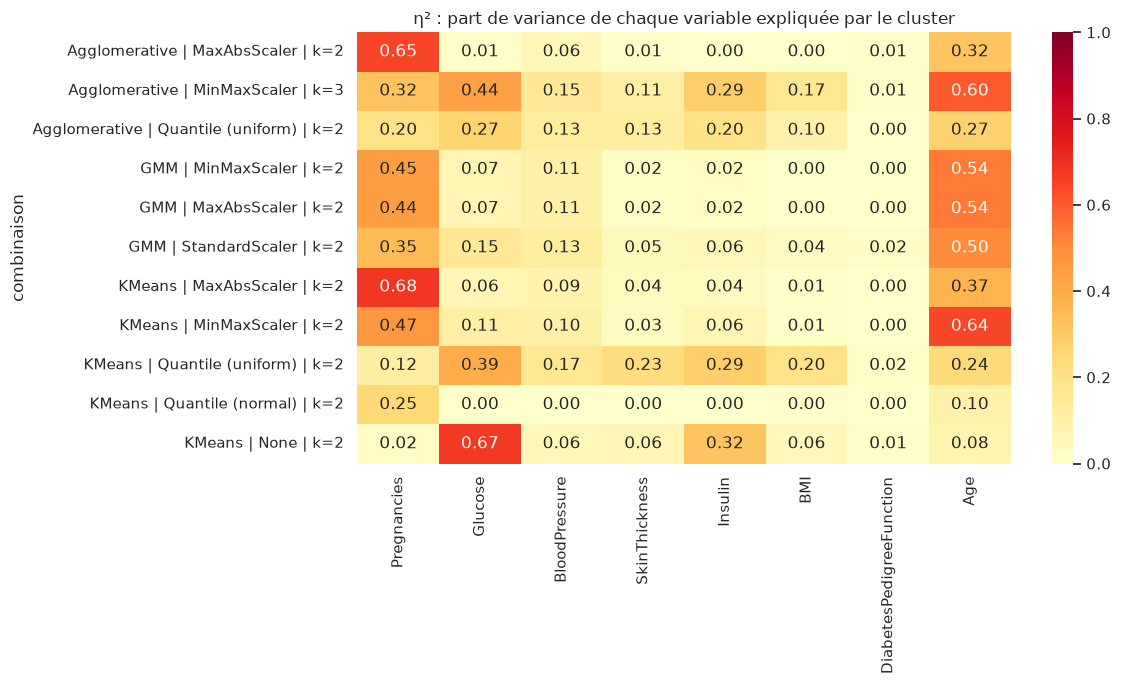

In [13]:
def eta_squared(values, labels):
    values = np.asarray(values, dtype=float)
    labels = np.asarray(labels)
    grand_mean = values.mean()
    ss_total = ((values - grand_mean) ** 2).sum()
    ss_between = sum(
        (labels == c).sum() * (values[labels == c].mean() - grand_mean) ** 2
        for c in np.unique(labels)
    )
    return ss_between / ss_total


RISK_VARS = ["Glucose", "BMI", "DiabetesPedigreeFunction"]
DEMO_VARS = ["Pregnancies", "Age"]

combos = [(r.model, r.scaler, int(r.k), "shortlist") for r in shortlist.itertuples()]
combos += [("KMeans", "Quantile (normal)", 2, "référence"),
        ("KMeans", "None", 2, "référence")]

eta_rows = []
profile_rows = []

for model_name, scaler_name, k, kind in combos:
    X_scaled = scale_data(X_model, scaler_name)
    labels = make_model(model_name, k).fit_predict(X_scaled)
    name = f"{model_name} | {scaler_name} | k={k}"

    etas = {col: eta_squared(df_clean[col], labels) for col in FEATURES}
    eta_rows.append({
        "combinaison": name,
        "type": kind,
        **etas,
        "eta_risque": np.mean([etas[c] for c in RISK_VARS]),
        "eta_demo": np.mean([etas[c] for c in DEMO_VARS]),
    })

    sizes = pd.Series(labels).value_counts(normalize=True).sort_index() * 100
    means = df_clean.groupby(labels)[RISK_VARS].mean()
    means.insert(0, "taille_%", sizes.round(1))
    means.insert(0, "combinaison", name)
    means.index.name = "cluster"
    profile_rows.append(means.reset_index())

eta_table = pd.DataFrame(eta_rows).set_index("combinaison")
display(eta_table.round(3))

plt.figure(figsize=(12, 7))
sns.heatmap(
    eta_table[FEATURES],
    annot=True, fmt=".2f", cmap="YlOrRd", vmin=0, vmax=1,
)
plt.title("η² : part de variance de chaque variable expliquée par le cluster")
plt.tight_layout()
plt.show()

In [14]:
profiles = pd.concat(profile_rows, ignore_index=True)
display(profiles.round(2))

,cluster,combinaison,taille_%,Glucose,BMI,DiabetesPedigreeFunction
0,0,Agglomerative | MaxAbsScaler | k=2,58.6,119.03,32.45,0.50
1,1,Agglomerative | MaxAbsScaler | k=2,41.4,125.33,32.43,0.44
2,0,Agglomerative | MinMaxScaler | k=3,56.5,104.93,30.68,0.45
3,1,Agglomerative | MinMaxScaler | k=3,32.3,137.45,32.93,0.49
4,2,Agglomerative | MinMaxScaler | k=3,11.2,160.37,39.93,0.56
5,0,Agglomerative | Quantile (uniform) | k=2,67.1,132.66,33.94,0.49
6,1,Agglomerative | Quantile (uniform) | k=2,32.9,99.21,29.40,0.44
7,0,GMM | MinMaxScaler | k=2,48.7,113.32,32.06,0.47
8,1,GMM | MinMaxScaler | k=2,51.3,129.54,32.80,0.47
9,0,GMM | MaxAbsScaler | k=2,48.6,113.29,32.07,0.48


### 11.6 Grille métabolique complète

La présélection précédente reposait sur un score dominé par la silhouette. Nous la remplaçons par un examen **exhaustif** : pour chaque modèle, scaler et k (de 2 à 5), nous mesurons où se situe la séparation.

Nous définissons trois indicateurs (tous basés sur η², déjà défini en 11.5) :

- `eta_metabo` : moyenne de η² sur les **6 variables métaboliques** (Glucose, BloodPressure, SkinThickness, Insulin, BMI, DPF) ;
- `eta_demo` : moyenne de η² sur **Pregnancies et Age** ;
- `ecart_metabo` = `eta_metabo` − `eta_demo` : s'il est positif, les clusters séparent plutôt sur le métabolisme ; s'il est négatif, ils séparent plutôt sur l'âge et les grossesses.

Nous gardons seulement les partitions dont le plus petit cluster fait au moins 5 % des patients et dont la stabilité ARI est d'au moins 0,70, puis nous classons par `eta_metabo`.

> **Pourquoi ce critère ?** L'objectif du projet est de repérer des profils à risque de diabète. Un clustering qui sépare les patients selon l'âge et le nombre de grossesses est stable et propre, mais il ne répond pas à la question posée.

In [15]:
METABO_VARS = ["Glucose", "BloodPressure", "SkinThickness",
            "Insulin", "BMI", "DiabetesPedigreeFunction"]
DEMO_VARS = ["Pregnancies", "Age"]
GRID_SCALERS = [s for s in SCALERS if s not in ("None", "Quantile (normal)")]
GRID_K = range(2, 6)

rows = []
for scaler_name in GRID_SCALERS:
    X_scaled = scale_data(X_model, scaler_name)
    for model_name in BENCHMARK_MODELS:
        for k in GRID_K:
            labels = make_model(model_name, k).fit_predict(X_scaled)
            etas = {c: eta_squared(df_clean[c], labels) for c in FEATURES}
            eta_metabo = np.mean([etas[c] for c in METABO_VARS])
            eta_demo = np.mean([etas[c] for c in DEMO_VARS])
            rows.append({
                "model": model_name, "scaler": scaler_name, "k": k,
                "eta_glucose": etas["Glucose"],
                "eta_metabo": eta_metabo,
                "eta_demo": eta_demo,
                "ecart_metabo": eta_metabo - eta_demo,
            })

metabo_grid = pd.DataFrame(rows).merge(
    benchmark_df[["model", "scaler", "k", "silhouette", "stability_mean",
                "min_cluster_pct"]],
    on=["model", "scaler", "k"],
)
metabo_grid.to_csv(REPORTS_DIR / "clustering_metabolic_grid.csv", index=False)

eligible = metabo_grid[
    (metabo_grid["min_cluster_pct"] >= 5)
    & (metabo_grid["stability_mean"] >= 0.70)
]

for model_name in BENCHMARK_MODELS:
    print("=" * 70)
    print(f"{model_name} — top 8 par eta_metabo (min cluster ≥ 5 %, ARI ≥ 0,70)")
    display(
        eligible[eligible["model"] == model_name]
        .sort_values("eta_metabo", ascending=False)
        .head(8)
        .round(3)
        .reset_index(drop=True)
    )

KMeans — top 8 par eta_metabo (min cluster ≥ 5 %, ARI ≥ 0,70)


,model,scaler,k,eta_glucose,eta_metabo,eta_demo,ecart_metabo,silhouette,stability_mean,min_cluster_pct
0,KMeans,Quantile (uniform),5,0.464,0.356,0.448,-0.091,0.165,0.702,16.667
1,KMeans,PowerTransformer,4,0.429,0.304,0.502,-0.197,0.156,0.826,21.224
2,KMeans,Quantile (uniform),4,0.467,0.302,0.495,-0.193,0.172,0.796,21.875
3,KMeans,RobustScaler,3,0.318,0.264,0.449,-0.184,0.184,0.913,27.474
4,KMeans,MinMaxScaler,4,0.585,0.255,0.604,-0.349,0.189,0.844,19.922
5,KMeans,StandardScaler,3,0.248,0.243,0.530,-0.287,0.193,0.901,27.474
6,KMeans,PowerTransformer,3,0.256,0.235,0.511,-0.276,0.186,0.934,25.911
7,KMeans,RobustScaler,2,0.372,0.235,0.135,0.100,0.203,0.864,49.089


GMM — top 8 par eta_metabo (min cluster ≥ 5 %, ARI ≥ 0,70)


,model,scaler,k,eta_glucose,eta_metabo,eta_demo,ecart_metabo,silhouette,stability_mean,min_cluster_pct
0,GMM,RobustScaler,2,0.157,0.077,0.420,-0.343,0.143,0.877,47.786
1,GMM,StandardScaler,2,0.154,0.074,0.423,-0.349,0.164,0.877,47.917
2,GMM,MaxAbsScaler,2,0.071,0.037,0.490,-0.452,0.176,0.829,48.568
3,GMM,MinMaxScaler,2,0.071,0.037,0.492,-0.454,0.226,0.827,48.698
4,GMM,RobustScaler,3,0.081,0.034,0.375,-0.341,0.007,0.726,23.438
5,GMM,Quantile (uniform),2,0.000,0.009,0.025,-0.017,0.010,0.942,38.021


Agglomerative — top 8 par eta_metabo (min cluster ≥ 5 %, ARI ≥ 0,70)


,model,scaler,k,eta_glucose,eta_metabo,eta_demo,ecart_metabo,silhouette,stability_mean,min_cluster_pct


## 12. K-Means : méthode du coude et silhouette

### 12.1 Rappel des deux outils

**Méthode du coude (elbow)**
- **C'est quoi ?** Un graphique de l'inertie (somme des carrés des distances aux centroïdes) en fonction de *k*.
- **Comment ça marche ?** L'inertie baisse toujours quand *k* augmente. Au début la baisse est forte (chaque nouveau cluster capte une vraie structure), puis elle devient faible (on découpe seulement du bruit). Le point où la courbe « se plie » est le **coude**.
- **À quoi ça sert ?** Trouver le *k* au-delà duquel un cluster de plus n'apporte presque plus rien.
- **Limite :** sur des données sans séparation nette, la courbe est souvent lisse et le coude difficile à voir. C'est pourquoi on le combine avec la silhouette.

**Score de silhouette** (déjà défini en section 8) : plus il est haut, mieux les points sont placés dans leur cluster.

### 12.2 Comparer des scalers : variance expliquée
Un scaler change l'échelle des données, donc les **inertie brutes ne sont pas comparables** d'un scaler à l'autre. Nous les convertissons en **part de variance expliquée** :

- **Variance expliquée par les clusters** = 1 − (inertie ÷ inertie totale).
- **Inertie totale** = inertie avec un seul cluster (somme des carrés des distances à la moyenne globale).
- **Lecture :** 0 % = les clusters n'expliquent rien ; 100 % = tous les points sont sur leur centroïde. **Exemple :** 30 % signifie que les centroïdes expliquent 30 % de la dispersion des patients.

Nous calculons aussi la **baisse relative de l'inertie** entre *k−1* et *k* : si elle passe de 25 % à 8 %, le coude est autour de *k*−1.

### 12.3 Courbes et choix de k
Nous affichons, pour chaque scaler : la courbe d'inertie, la courbe de silhouette, puis un tableau récapitulatif (variance expliquée, baisse relative, silhouette, stabilité ARI, η² métabolique).

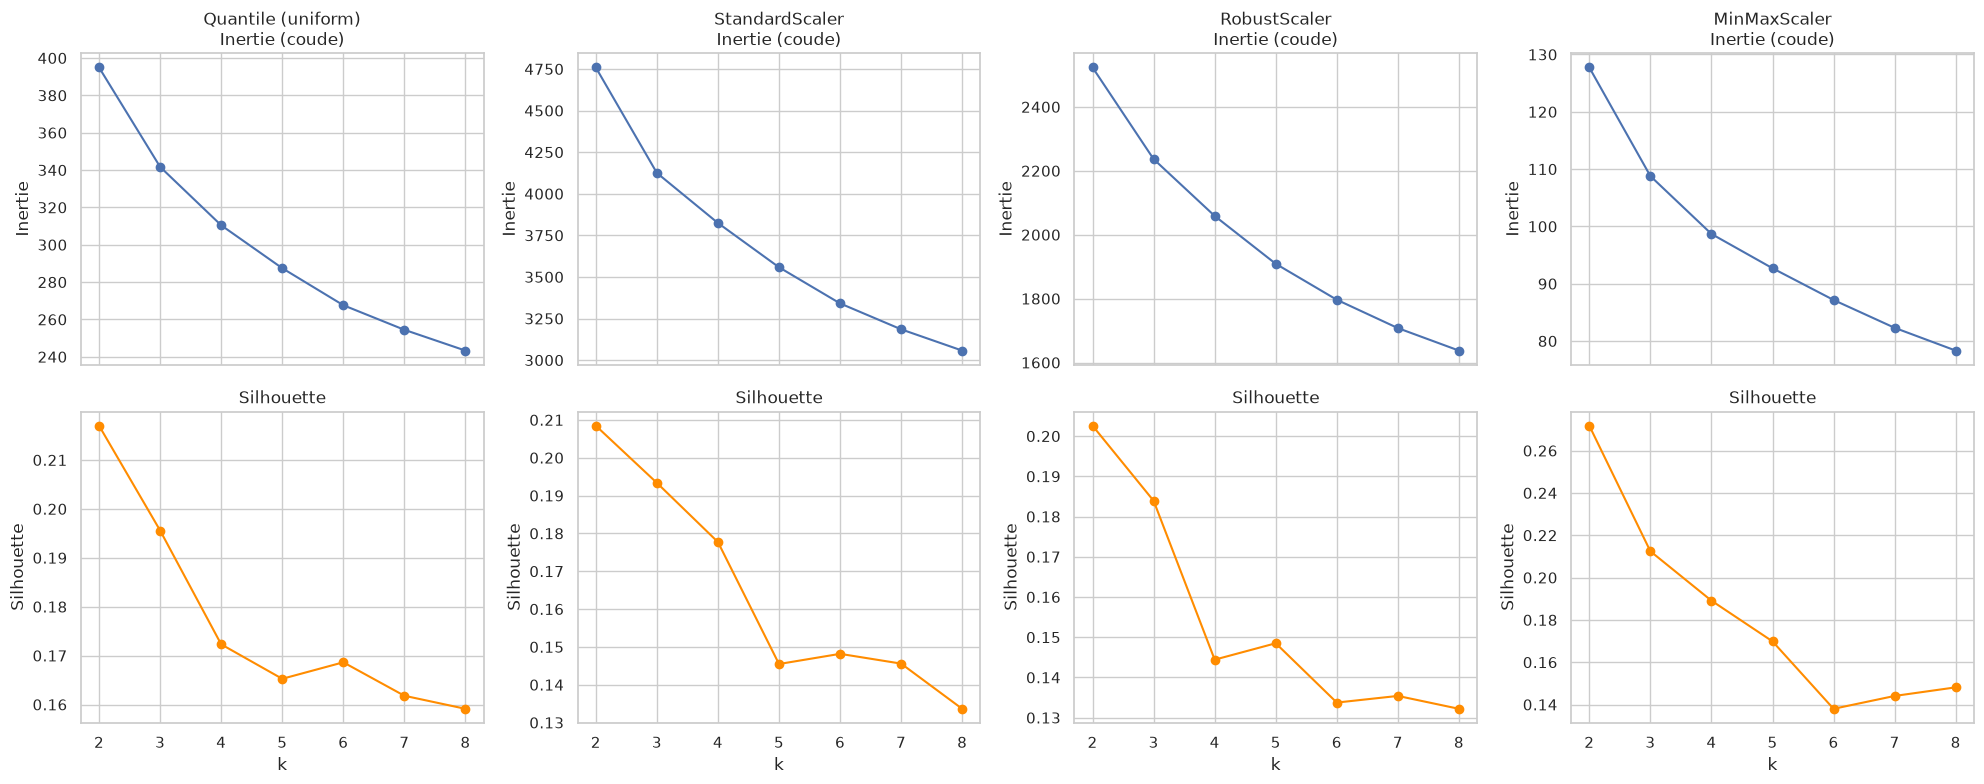

K-Means — Quantile (uniform)


,k,inertia,variance_expliquee_%,baisse_relative_%,silhouette,min_cluster_%,eta_metabo,eta_demo,stability_mean
0,2,394.919,24.321,24.321,0.217,46.875,0.215,0.182,0.902
1,3,341.690,34.521,13.479,0.196,24.740,0.233,0.518,0.914
2,4,310.422,40.513,9.151,0.172,21.875,0.302,0.495,0.796
3,5,287.437,44.918,7.404,0.165,16.667,0.356,0.448,0.702
4,6,267.616,48.716,6.896,0.169,12.891,0.390,0.513,0.776
5,7,254.450,51.239,4.920,0.162,11.328,0.405,0.527,0.624
6,8,243.316,53.373,4.376,0.159,8.594,0.430,0.519,0.600


K-Means — StandardScaler


,k,inertia,variance_expliquee_%,baisse_relative_%,silhouette,min_cluster_%,eta_metabo,eta_demo,stability_mean
0,2,4758.880,22.544,22.544,0.208,47.266,0.203,0.254,0.891
1,3,4125.004,32.861,13.320,0.193,27.474,0.243,0.530,0.901
2,4,3824.137,37.758,7.294,0.178,18.490,0.314,0.539,0.613
3,5,3558.021,42.090,6.959,0.145,11.589,0.379,0.527,0.645
4,6,3340.850,45.624,6.104,0.148,9.505,0.413,0.550,0.668
5,7,3185.122,48.159,4.661,0.146,9.115,0.445,0.548,0.692
6,8,3057.235,50.240,4.015,0.134,9.245,0.469,0.548,0.540


K-Means — RobustScaler


,k,inertia,variance_expliquee_%,baisse_relative_%,silhouette,min_cluster_%,eta_metabo,eta_demo,stability_mean
0,2,2523.192,22.927,22.927,0.203,49.089,0.235,0.135,0.864
1,3,2236.496,31.684,11.362,0.184,27.474,0.264,0.449,0.913
2,4,2058.678,37.116,7.951,0.144,18.359,0.338,0.436,0.676
3,5,1908.895,41.691,7.276,0.148,14.323,0.405,0.418,0.581
4,6,1796.416,45.127,5.892,0.134,11.328,0.412,0.511,0.577
5,7,1707.758,47.835,4.935,0.135,10.156,0.464,0.453,0.604
6,8,1637.388,49.985,4.121,0.132,9.635,0.467,0.487,0.531


K-Means — MinMaxScaler


,k,inertia,variance_expliquee_%,baisse_relative_%,silhouette,min_cluster_%,eta_metabo,eta_demo,stability_mean
0,2,127.729,28.305,28.305,0.272,38.281,0.054,0.555,0.905
1,3,108.782,38.940,14.833,0.212,24.740,0.204,0.566,0.854
2,4,98.685,44.608,9.282,0.189,19.922,0.255,0.604,0.844
3,5,92.698,47.968,6.066,0.170,12.109,0.261,0.680,0.644
4,6,87.162,51.076,5.973,0.138,12.500,0.307,0.679,0.636
5,7,82.303,53.803,5.574,0.144,9.505,0.357,0.666,0.669
6,8,78.327,56.035,4.831,0.148,8.073,0.364,0.727,0.683


In [16]:
KMEANS_SCALERS = ["Quantile (uniform)", "StandardScaler",
                "RobustScaler", "MinMaxScaler"]
KMEANS_K = range(2, 9)

kmeans_rows = []

for scaler_name in KMEANS_SCALERS:
    X_scaled = scale_data(X_model, scaler_name)

    total_inertia = ((X_scaled - X_scaled.mean(axis=0)) ** 2).sum()

    previous_inertia = total_inertia
    for k in KMEANS_K:
        model = make_model("KMeans", k)
        labels = model.fit_predict(X_scaled)

        etas = {c: eta_squared(df_clean[c], labels) for c in FEATURES}

        kmeans_rows.append({
            "scaler": scaler_name,
            "k": k,
            "inertia": model.inertia_,
            "variance_expliquee_%": (1 - model.inertia_ / total_inertia) * 100,
            "baisse_relative_%": (1 - model.inertia_ / previous_inertia) * 100,
            "silhouette": silhouette_score(X_scaled, labels),
            "min_cluster_%": pd.Series(labels).value_counts(normalize=True).min() * 100,
            "eta_metabo": np.mean([etas[c] for c in METABO_VARS]),
            "eta_demo": np.mean([etas[c] for c in DEMO_VARS]),
        })
        previous_inertia = model.inertia_

kmeans_curves = pd.DataFrame(kmeans_rows).merge(
    benchmark_df[benchmark_df["model"] == "KMeans"][["scaler", "k", "stability_mean"]],
    on=["scaler", "k"],
)
kmeans_curves.to_csv(REPORTS_DIR / "kmeans_curves.csv", index=False)

fig, axes = plt.subplots(2, len(KMEANS_SCALERS), figsize=(20, 8), sharex=True)

for col, scaler_name in enumerate(KMEANS_SCALERS):
    sub = kmeans_curves[kmeans_curves["scaler"] == scaler_name]

    axes[0, col].plot(sub["k"], sub["inertia"], marker="o")
    axes[0, col].set_title(f"{scaler_name}\nInertie (coude)")
    axes[0, col].set_ylabel("Inertie")

    axes[1, col].plot(sub["k"], sub["silhouette"], marker="o", color="darkorange")
    axes[1, col].set_title("Silhouette")
    axes[1, col].set_ylabel("Silhouette")
    axes[1, col].set_xlabel("k")

plt.tight_layout()
plt.show()

for scaler_name in KMEANS_SCALERS:
    print("=" * 70)
    print(f"K-Means — {scaler_name}")
    display(
        kmeans_curves[kmeans_curves["scaler"] == scaler_name]
        .drop(columns="scaler")
        .round(3)
        .reset_index(drop=True)
    )

### 12.4 Choix de k : synthèse

| Critère | Lecture |
|---|---|
| Coude | Pas de coude net : la baisse relative décroît progressivement (24 % → 13 % → 9 % → 7 %). Seule la première baisse (k = 2) est nettement plus grande que les suivantes. |
| Silhouette | Maximale pour **k = 2** avec les quatre scalers. |
| Stabilité (ARI) | Bonne jusqu'à k = 3 (≈ 0,90), puis dégradation. |
| η² | À partir de k = 3, les clusters séparent surtout selon **Age et Pregnancies** (`eta_demo` ≈ 0,5). |

**Décision : k = 2.** C'est le seul k où le partitionnement reste stable, a la meilleure silhouette et sépare plutôt sur le métabolisme. Il correspond aussi à l'objectif du projet (risque élevé / risque faible).

> **Limite à mentionner :** la silhouette reste proche de 0,2. Les patients forment un **continuum**, pas des groupes naturellement séparés. K-Means découpe ce continuum en deux profils.

### 12.5 Duel final : Quantile (uniform) vs RobustScaler

Deux scalers restent en lice. Nous les comparons sur :

- **Stabilité renforcée** : 30 répétitions au lieu de 10, pour réduire le bruit de l'estimation.
- **Accord entre les deux partitions (ARI)** : si l'ARI est proche de 1, les deux scalers produisent presque les mêmes groupes et le choix a peu d'importance.
- **Profils cliniques** : moyennes en unités d'origine et nombre de critères de risque dépassés (Glucose > 126, BMI > 30, DPF > 0,5).
- **Profil standardisé (z-score)** : écart de chaque variable à la moyenne globale, en nombre d'écarts-types. Exemple : un z de +1 sur Glucose signifie que la glycémie moyenne du cluster est un écart-type au-dessus de la moyenne globale.

Les clusters sont renumérotés par glycémie moyenne croissante : le cluster 0 est toujours le plus bas.

K-Means | Quantile (uniform) | k=2
Stabilité ARI (30 répétitions) : 0.895 ± 0.068
Silhouette : 0.217


,taille_%,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,criteres_depasses
0,46.88,2.59,101.36,67.04,24.08,97.27,29.18,0.42,27.09,0
1,53.12,4.95,139.54,77.04,33.16,201.60,35.32,0.51,38.67,3


K-Means | RobustScaler | k=2
Stabilité ARI (30 répétitions) : 0.883 ± 0.080
Silhouette : 0.203


,taille_%,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,criteres_depasses
0,49.09,2.78,102.72,67.10,23.79,100.08,28.78,0.42,28.25,0
1,50.91,4.87,139.89,77.41,33.84,203.42,35.97,0.52,38.05,3


ARI entre les deux partitions : 0.788


RobustScaler,0,1
Quantile (uniform),,
0,347,13
1,30,378


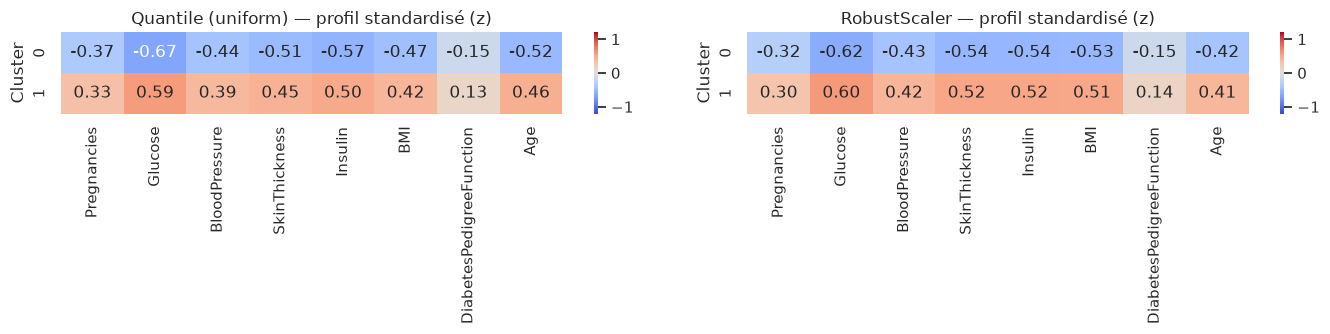

In [17]:
DUEL = ["Quantile (uniform)", "RobustScaler"]
K_FINAL = 2

duel_labels = {}
profile_tables = {}

for scaler_name in DUEL:
    X_scaled = scale_data(X_model, scaler_name)
    labels = make_model("KMeans", K_FINAL).fit_predict(X_scaled)

    order = df_clean.groupby(labels)["Glucose"].mean().sort_values().index
    mapping = {old: new for new, old in enumerate(order)}
    labels = np.array([mapping[l] for l in labels])
    duel_labels[scaler_name] = labels

    stab_mean, stab_std = stability_score(X_scaled, "KMeans", K_FINAL, n_repeats=30)

    prof = df_clean.groupby(labels).mean()
    prof.insert(0, "taille_%", pd.Series(labels).value_counts(normalize=True).sort_index() * 100)
    prof["criteres_depasses"] = (
        (prof["Glucose"] > 126).astype(int)
        + (prof["BMI"] > 30).astype(int)
        + (prof["DiabetesPedigreeFunction"] > 0.5).astype(int)
    )
    profile_tables[scaler_name] = prof

    print("=" * 70)
    print(f"K-Means | {scaler_name} | k={K_FINAL}")
    print(f"Stabilité ARI (30 répétitions) : {stab_mean:.3f} ± {stab_std:.3f}")
    print(f"Silhouette : {silhouette_score(X_scaled, labels):.3f}")
    display(prof.round(2))

ari_between = adjusted_rand_score(duel_labels[DUEL[0]], duel_labels[DUEL[1]])
print("=" * 70)
print(f"ARI entre les deux partitions : {ari_between:.3f}")
display(pd.crosstab(
    pd.Series(duel_labels[DUEL[0]], name=DUEL[0]),
    pd.Series(duel_labels[DUEL[1]], name=DUEL[1]),
))

fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
global_mean, global_std = df_clean.mean(), df_clean.std()

for ax, scaler_name in zip(axes, DUEL):
    z = (df_clean.groupby(duel_labels[scaler_name]).mean() - global_mean) / global_std
    sns.heatmap(z, annot=True, fmt=".2f", cmap="coolwarm", center=0,
                vmin=-1.2, vmax=1.2, ax=ax)
    ax.set_title(f"{scaler_name} — profil standardisé (z)")
    ax.set_ylabel("Cluster")

plt.tight_layout()
plt.show()

## 13. Gaussian Mixture Model : BIC/AIC et types de covariance

### 13.1 Les types de covariance
Chaque cluster du GMM est une « cloche » en 8 dimensions. Le **type de covariance** définit la forme autorisée de cette cloche :

| Type | Forme des clusters | Nombre de paramètres de forme (8 variables, k clusters) | Analogie |
|---|---|---|---|
| `spherical` | Boule, une seule taille par cluster | k | Équivalent probabiliste de K-Means |
| `diag` | Ellipse alignée sur les axes (variables indépendantes) | 8 × k | Chaque variable a sa propre dispersion |
| `tied` | Même ellipse inclinée pour tous les clusters | 36 | Tous les clusters ont la même forme |
| `full` | Ellipse inclinée, différente pour chaque cluster | 36 × k | Le plus flexible, mais le plus risqué avec 768 patients |

**Exemple :** pour k = 3, `spherical` estime 3 paramètres de forme, `full` en estime 108. Avec 768 patients, `full` a beaucoup de liberté pour s'ajuster à du bruit, ce qui explique les composantes dégénérées observées au benchmark.

### 13.2 BIC et AIC
- **C'est quoi ?** Deux scores qui mesurent la qualité d'ajustement du modèle **moins une pénalité** sur le nombre de paramètres.
- **Comment ça marche ?** `BIC = −2 × log-vraisemblance + p × ln(n)` et `AIC = −2 × log-vraisemblance + 2 × p`, avec *p* le nombre de paramètres et *n* le nombre de patients. La pénalité du BIC est plus forte dès que n > 7.
- **Exemple :** ajouter un cluster améliore la vraisemblance de 30, mais coûte 20 paramètres. Pénalité BIC = 20 × ln(768) ≈ 133 : le BIC augmente, donc le cluster n'est **pas justifié**.
- **À quoi ça sert ?** Choisir *k* et le type de covariance. **Plus bas = mieux.**
- **Limite :** BIC et AIC sont comparables entre *k* et entre types de covariance **pour un même scaler**. Ils ne sont **pas comparables entre scalers** (la vraisemblance dépend de l'espace des données).

### 13.3 Ce que nous regardons
Le BIC est un critère **statistique** ; il ne garantit pas que les clusters aient un sens clinique. Nous le combinons donc avec la stabilité, la taille minimale des clusters et η² (`eta_metabo` contre `eta_demo`).

✓ Scaler terminé : StandardScaler
✓ Scaler terminé : RobustScaler
✓ Scaler terminé : Quantile (uniform)


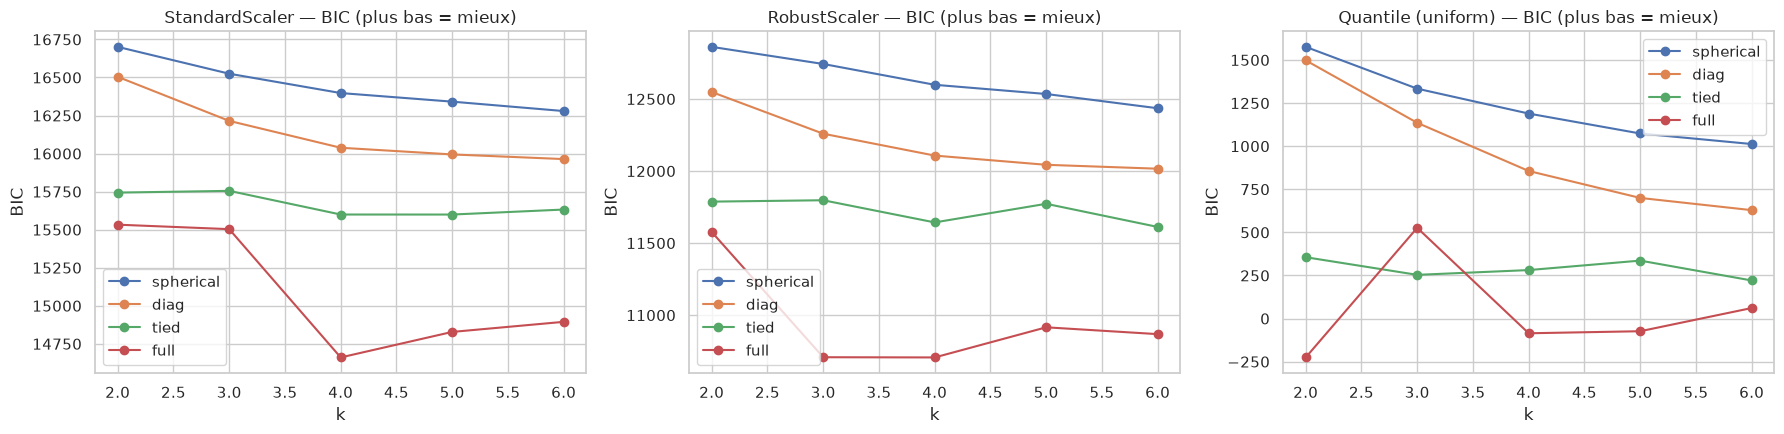

GMM — BIC — StandardScaler


k,2,3,4,5,6
covariance,,,,,
diag,16504.0,16215.0,16038.0,15994.0,15964.0
full,15533.0,15504.0,14660.0,14828.0,14894.0
spherical,16701.0,16525.0,16398.0,16341.0,16280.0
tied,15744.0,15755.0,15600.0,15599.0,15632.0


GMM — BIC — RobustScaler


k,2,3,4,5,6
covariance,,,,,
diag,12548.0,12259.0,12107.0,12043.0,12016.0
full,11577.0,10708.0,10707.0,10916.0,10868.0
spherical,12862.0,12743.0,12598.0,12535.0,12436.0
tied,11788.0,11797.0,11643.0,11773.0,11612.0


GMM — BIC — Quantile (uniform)


k,2,3,4,5,6
covariance,,,,,
diag,1498.0,1136.0,856.0,700.0,629.0
full,-226.0,526.0,-85.0,-74.0,61.0
spherical,1576.0,1334.0,1189.0,1074.0,1012.0
tied,356.0,254.0,281.0,336.0,221.0


GMM — top 12 par eta_metabo (min cluster ≥ 5 %, ARI ≥ 0,70)


,scaler,covariance,k,bic,aic,silhouette,min_cluster_%,eta_metabo,eta_demo,stability_mean,ecart_metabo
0,Quantile (uniform),spherical,5,1073.501,845.955,0.164,13.932,0.341,0.478,0.724,-0.137
1,StandardScaler,spherical,4,16397.794,16216.686,0.122,16.276,0.300,0.501,0.784,-0.201
2,StandardScaler,spherical,3,16524.906,16390.236,0.199,23.438,0.243,0.523,0.871,-0.281
3,Quantile (uniform),spherical,3,1333.576,1198.906,0.197,22.266,0.232,0.496,0.918,-0.264
4,Quantile (uniform),diag,3,1135.513,903.323,0.184,30.078,0.220,0.540,0.906,-0.320
5,RobustScaler,spherical,2,12861.642,12773.410,0.186,40.104,0.211,0.160,0.813,0.052
6,RobustScaler,diag,3,12259.003,12026.813,0.159,20.312,0.205,0.532,0.862,-0.326
7,StandardScaler,diag,3,16214.872,15982.682,0.176,20.312,0.205,0.532,0.872,-0.326
8,Quantile (uniform),diag,2,1497.786,1344.541,0.201,40.104,0.201,0.098,0.801,0.104
9,StandardScaler,tied,3,15755.132,15467.217,0.190,19.010,0.200,0.584,0.778,-0.384


In [18]:
GMM_SCALERS = ["StandardScaler", "RobustScaler", "Quantile (uniform)"]
COV_TYPES = ["spherical", "diag", "tied", "full"]
GMM_K = range(2, 7)

gmm_rows = []

for scaler_name in GMM_SCALERS:
    X_scaled = scale_data(X_model, scaler_name)

    for cov in COV_TYPES:
        for k in GMM_K:
            model = make_model("GMM", k, covariance_type=cov)
            labels = model.fit_predict(X_scaled)

            etas = {c: eta_squared(df_clean[c], labels) for c in FEATURES}
            stab_mean, _ = stability_score(
                X_scaled, "GMM", k, n_repeats=10, covariance_type=cov
            )
            n_clusters_found = len(np.unique(labels))
            sizes = pd.Series(labels).value_counts(normalize=True) * 100

            gmm_rows.append({
                "scaler": scaler_name,
                "covariance": cov,
                "k": k,
                "bic": model.bic(X_scaled),
                "aic": model.aic(X_scaled),
                "silhouette": (silhouette_score(X_scaled, labels)
                            if n_clusters_found > 1 else np.nan),
                "min_cluster_%": sizes.min(),
                "eta_metabo": np.mean([etas[c] for c in METABO_VARS]),
                "eta_demo": np.mean([etas[c] for c in DEMO_VARS]),
                "stability_mean": stab_mean,
            })

    print(f"✓ Scaler terminé : {scaler_name}")

gmm_df = pd.DataFrame(gmm_rows)
gmm_df["ecart_metabo"] = gmm_df["eta_metabo"] - gmm_df["eta_demo"]
gmm_df.to_csv(REPORTS_DIR / "gmm_covariance_grid.csv", index=False)

fig, axes = plt.subplots(1, len(GMM_SCALERS), figsize=(18, 4.5))

for ax, scaler_name in zip(axes, GMM_SCALERS):
    for cov in COV_TYPES:
        sub = gmm_df[(gmm_df["scaler"] == scaler_name) & (gmm_df["covariance"] == cov)]
        ax.plot(sub["k"], sub["bic"], marker="o", label=cov)
    ax.set_title(f"{scaler_name} — BIC (plus bas = mieux)")
    ax.set_xlabel("k")
    ax.set_ylabel("BIC")
    ax.legend()

plt.tight_layout()
plt.show()

for scaler_name in GMM_SCALERS:
    print("=" * 70)
    print(f"GMM — BIC — {scaler_name}")
    display(
        gmm_df[gmm_df["scaler"] == scaler_name]
        .pivot(index="covariance", columns="k", values="bic")
        .round(0)
    )

gmm_eligible = gmm_df[
    (gmm_df["min_cluster_%"] >= 5) & (gmm_df["stability_mean"] >= 0.70)
].sort_values("eta_metabo", ascending=False)

print("=" * 70)
print("GMM — top 12 par eta_metabo (min cluster ≥ 5 %, ARI ≥ 0,70)")
display(gmm_eligible.head(12).round(3).reset_index(drop=True))

### 12.6 Décision finale pour K-Means

| Élément | Décision |
|---|---|
| Nombre de clusters | **k = 2** |
| Scaler | **RobustScaler** |

**Pourquoi RobustScaler plutôt que Quantile (uniform) ?**
- Les deux donnent presque la même partition : ARI entre les deux = 0,788 ; seuls 43 patients sur 768 (5,6 %) changent de groupe.
- Les différences de stabilité (0,883 vs 0,895) sont inférieures à l'écart-type (≈ 0,07 à 0,08) : elles ne sont pas significatives.
- RobustScaler sépare mieux selon le métabolisme (`ecart_metabo` = +0,100 contre +0,033).
- Il conserve les **distances réelles**, alors que le Quantile Transformer ne conserve que les rangs et écrase les patients extrêmes (qui sont les profils à risque).
- Il est cohérent avec la stratégie de conservation des outliers du notebook 01.

**Profil obtenu :** le cluster 0 (49 %) ne dépasse aucun des trois seuils de risque ; le cluster 1 (51 %) les dépasse tous les trois (Glucose ≈ 140, BMI ≈ 36, DPF ≈ 0,52). Cela correspond directement à la colonne `risk_category` du projet.

> **Limite :** la silhouette (≈ 0,2) montre que les patients forment un continuum. K-Means le découpe en deux profils ; ce ne sont pas des groupes naturellement séparés.

### 13.4 Décision pour le GMM

- Le **BIC ne permet pas de choisir k** : pour `diag` et `spherical`, il diminue jusqu'à k = 6 sans minimum. Les données ne suivent pas un mélange de lois normales (variables discrètes, asymétriques, valeurs imputées).
- Le type `full` est dégénéré ou instable : aucune ligne `full` ne passe les filtres (taille ≥ 5 %, ARI ≥ 0,70). Son BIC négatif avec Quantile (uniform) est un signe de covariances quasi singulières.
- À partir de k = 3, les clusters séparent surtout selon Age et Pregnancies (`ecart_metabo` < 0).
- Seules les partitions à **k = 2** séparent plutôt selon le métabolisme.

**Décision :** le GMM est conservé comme **challenger** avec **Quantile (uniform), covariance `diag`, k = 2** (`ecart_metabo` = +0,104, ARI = 0,80). Le choix de k = 2 repose sur les critères cliniques et non sur le BIC.

## 14. Clustering hiérarchique : dendrogramme et critères de liaison

### 14.1 Les critères de liaison (linkage)
Le clustering agglomératif fusionne les deux groupes les plus proches. Le **linkage** définit la distance entre deux **groupes**.

Exemple : deux groupes de patients (glycémie) A = {90, 95, 100} et B = {180, 185, 190}.

| Linkage | Distance entre groupes | Valeur sur l'exemple | Comportement |
|---|---|---|---|
| `single` | distance entre les deux points **les plus proches** | 180 − 100 = **80** | Crée des « chaînes » : un point intermédiaire suffit à relier deux groupes |
| `complete` | distance entre les deux points **les plus éloignés** | 190 − 90 = **100** | Groupes compacts, sensible aux outliers |
| `average` | **moyenne** des distances entre tous les couples | 810 / 9 = **90** | Compromis entre les deux |
| `ward` | augmentation de la **variance interne** si on fusionne | — | Groupes compacts de taille comparable (proche de K-Means) |

### 14.2 Le dendrogramme
- **C'est quoi ?** Un arbre qui montre l'ordre des fusions. L'axe vertical est la **distance de fusion**.
- **Comment le lire ?** On « coupe » l'arbre par une ligne horizontale ; le nombre de branches coupées donne le nombre de clusters.
- **Où couper ?** Juste avant un **grand saut** de hauteur : fusionner deux groupes très éloignés détruirait la structure. Sur notre mini-exemple, les fusions internes se font à 5-10 puis la dernière à ≈ 90 : on coupe à 2 clusters.

### 14.3 Corrélation cophénétique
- **C'est quoi ?** La corrélation entre les distances réelles entre patients et les hauteurs auxquelles ces patients sont fusionnés dans le dendrogramme.
- **Comment ça marche ?** Si deux patients sont éloignés, ils doivent être fusionnés tard (en haut de l'arbre). Une corrélation proche de **1** signifie que l'arbre représente fidèlement les distances.
- **À quoi ça sert ?** Comparer les linkages : le plus élevé déforme le moins les distances.
- **Limite :** elle mesure la fidélité de l'arbre, pas l'intérêt clinique des groupes.

### 14.4 Ce que nous testons
Linkages `ward`, `complete`, `average`, `single`, scalers RobustScaler, Quantile (uniform), StandardScaler et MinMaxScaler, k de 2 à 5. Pour chaque combinaison : silhouette, taille minimale, stabilité ARI, η² métabolique et démographique.

Au benchmark initial, le Ward était le moins stable des trois modèles. Nous vérifions si un autre linkage fait mieux.

In [19]:
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet
from scipy.spatial.distance import pdist

In [20]:
AGG_SCALERS = ["RobustScaler", "Quantile (uniform)", "StandardScaler", "MinMaxScaler"]
LINKAGES = ["ward", "complete", "average", "single"]
AGG_K = range(2, 6)

agg_rows = []
coph_rows = []

for scaler_name in AGG_SCALERS:
    X_scaled = scale_data(X_model, scaler_name)
    distances = pdist(X_scaled)

    for link in LINKAGES:
        Z = linkage(X_scaled, method=link)
        coph, _ = cophenet(Z, distances)
        coph_rows.append({"scaler": scaler_name, "linkage": link, "cophenetic": coph})

        for k in AGG_K:
            labels = make_model("Agglomerative", k, linkage=link).fit_predict(X_scaled)
            etas = {c: eta_squared(df_clean[c], labels) for c in FEATURES}
            sizes = pd.Series(labels).value_counts(normalize=True) * 100
            stab_mean, _ = stability_score(
                X_scaled, "Agglomerative", k, n_repeats=10, linkage=link
            )

            agg_rows.append({
                "scaler": scaler_name,
                "linkage": link,
                "k": k,
                "silhouette": silhouette_score(X_scaled, labels),
                "min_cluster_%": sizes.min(),
                "eta_metabo": np.mean([etas[c] for c in METABO_VARS]),
                "eta_demo": np.mean([etas[c] for c in DEMO_VARS]),
                "stability_mean": stab_mean,
            })

    print(f"✓ Scaler terminé : {scaler_name}")

agg_df = pd.DataFrame(agg_rows)
agg_df["ecart_metabo"] = agg_df["eta_metabo"] - agg_df["eta_demo"]
agg_df.to_csv(REPORTS_DIR / "agglomerative_linkage_grid.csv", index=False)

coph_df = pd.DataFrame(coph_rows)
print("=" * 70)
print("Corrélation cophénétique (plus haut = arbre plus fidèle)")
display(coph_df.pivot(index="scaler", columns="linkage", values="cophenetic").round(3))

strict = agg_df[(agg_df["min_cluster_%"] >= 5) & (agg_df["stability_mean"] >= 0.70)]
relaxed = agg_df[(agg_df["min_cluster_%"] >= 5) & (agg_df["stability_mean"] >= 0.50)]

print("=" * 70)
print(f"Éligibles stricts (cluster min ≥ 5 %, ARI ≥ 0,70) : {len(strict)} lignes")
display(strict.sort_values("eta_metabo", ascending=False).head(10).round(3).reset_index(drop=True))

print("=" * 70)
print(f"Éligibles assouplis (cluster min ≥ 5 %, ARI ≥ 0,50) : {len(relaxed)} lignes")
display(relaxed.sort_values("eta_metabo", ascending=False).head(10).round(3).reset_index(drop=True))

print("=" * 70)
print("Linkage single : taille du plus petit cluster (%)")
display(
    agg_df[agg_df["linkage"] == "single"]
    .pivot_table(index="scaler", columns="k", values="min_cluster_%")
    .round(2)
)

✓ Scaler terminé : RobustScaler
✓ Scaler terminé : Quantile (uniform)
✓ Scaler terminé : StandardScaler
✓ Scaler terminé : MinMaxScaler
Corrélation cophénétique (plus haut = arbre plus fidèle)


linkage,average,complete,single,ward
scaler,,,,
MinMaxScaler,0.667,0.458,0.528,0.515
Quantile (uniform),0.535,0.462,0.136,0.487
RobustScaler,0.624,0.407,0.581,0.399
StandardScaler,0.643,0.432,0.574,0.380


Éligibles stricts (cluster min ≥ 5 %, ARI ≥ 0,70) : 0 lignes


,scaler,linkage,k,silhouette,min_cluster_%,eta_metabo,eta_demo,stability_mean,ecart_metabo


Éligibles assouplis (cluster min ≥ 5 %, ARI ≥ 0,50) : 0 lignes


,scaler,linkage,k,silhouette,min_cluster_%,eta_metabo,eta_demo,stability_mean,ecart_metabo


Linkage single : taille du plus petit cluster (%)


k,2,3,4,5
scaler,,,,
MinMaxScaler,0.13,0.13,0.13,0.13
Quantile (uniform),0.13,0.13,0.13,0.13
RobustScaler,0.13,0.13,0.13,0.13
StandardScaler,0.13,0.13,0.13,0.13


RobustScaler : hauteurs des dernières fusions (de 2 à 11 clusters)
[36.71 22.48 18.61 16.   14.87 11.68 11.63 10.48  9.97  9.47]
Quantile (uniform) : hauteurs des dernières fusions (de 2 à 11 clusters)
[14.39 10.02  8.01  7.28  6.42  5.28  4.27  4.08  3.9   3.88]


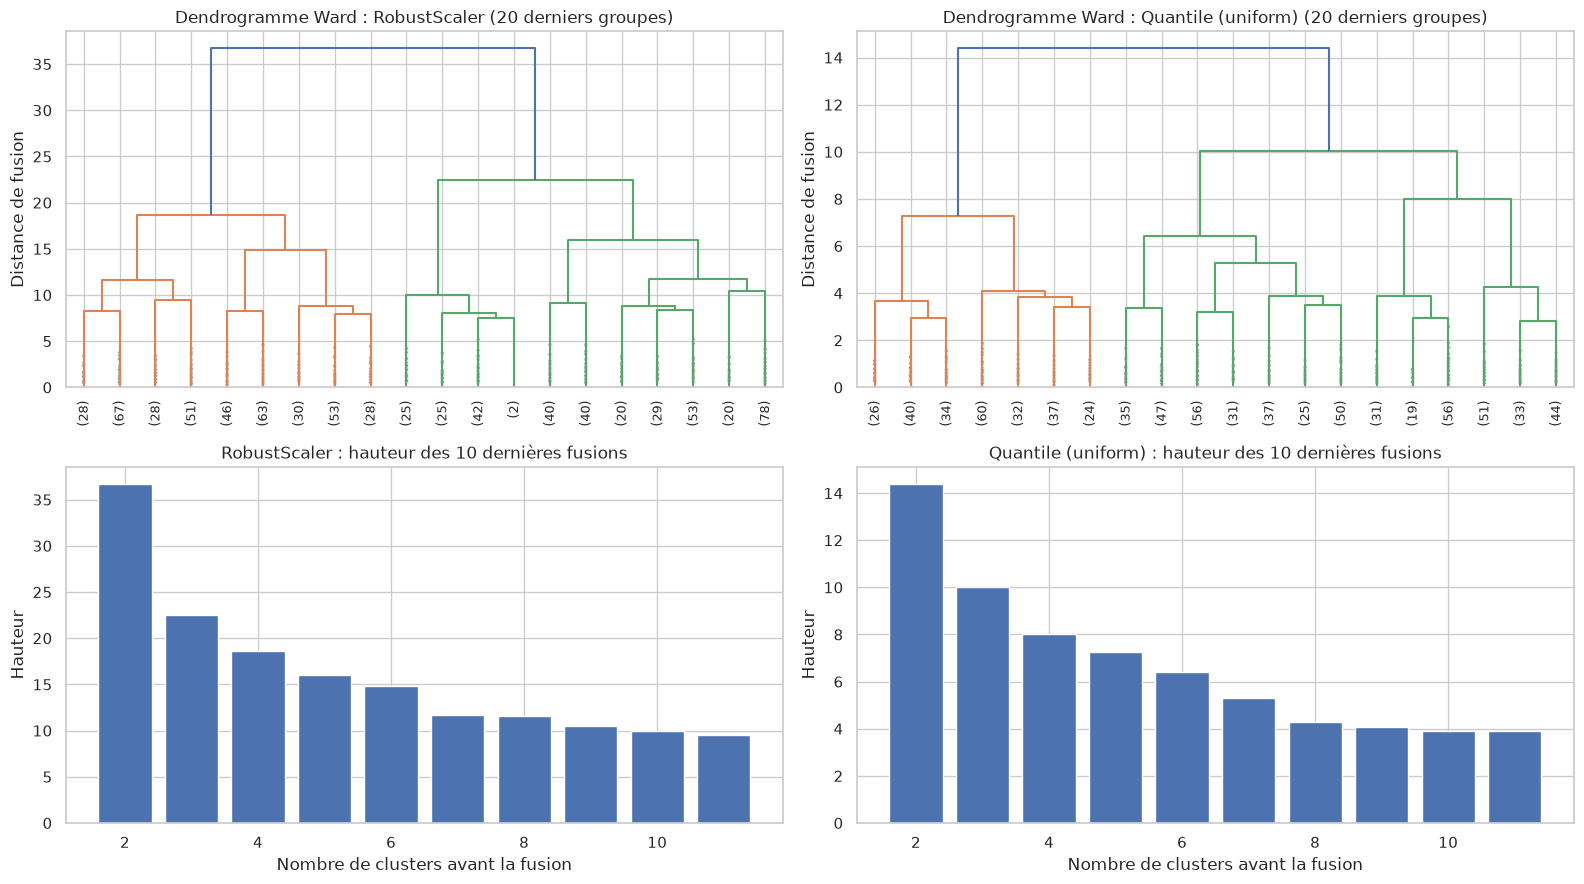

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(16, 9))

for col, scaler_name in enumerate(["RobustScaler", "Quantile (uniform)"]):
    X_scaled = scale_data(X_model, scaler_name)
    Z = linkage(X_scaled, method="ward")

    dendrogram(Z, truncate_mode="lastp", p=20, ax=axes[0, col],
            leaf_rotation=90, leaf_font_size=9, show_contracted=True)
    axes[0, col].set_title(f"Dendrogramme Ward : {scaler_name} (20 derniers groupes)")
    axes[0, col].set_ylabel("Distance de fusion")

    last_heights = Z[-10:, 2][::-1]
    axes[1, col].bar(range(2, 12), last_heights)
    axes[1, col].set_title(f"{scaler_name} : hauteur des 10 dernières fusions")
    axes[1, col].set_xlabel("Nombre de clusters avant la fusion")
    axes[1, col].set_ylabel("Hauteur")

    print(f"{scaler_name} : hauteurs des dernières fusions (de 2 à 11 clusters)")
    print(np.round(last_heights, 2))

plt.tight_layout()
plt.show()

### 14.5 Décision pour le clustering agglomératif

| Constat | Résultat |
|---|---|
| Partitions éligibles (cluster min ≥ 5 %, ARI ≥ 0,50) | **0** sur 64 combinaisons (4 scalers × 4 linkages × 4 valeurs de k) |
| Linkage `single` | Plus petit cluster = 0,13 % (1 patient) : **effet de chaîne**, un patient isolé est détaché à chaque étape |
| Corrélation cophénétique | 0,38 à 0,67 : l'arbre déforme les distances réelles. Ward, le plus proche de K-Means, est le plus faible (0,38 à 0,52) |
| Dendrogramme (Ward) | Le plus grand saut précède la dernière fusion (36,7 contre 22,5 avec RobustScaler) : indice modéré en faveur de **k = 2**. Ensuite la décroissance est lisse, sans second saut |

**Décision : le clustering agglomératif est écarté comme modèle final.** Aucune combinaison n'est à la fois stable et exploitable cliniquement.

Le dendrogramme reste utile comme **validation indépendante** : il soutient k = 2, comme K-Means.

> **Interprétation :** l'absence de gap entre groupes (chaînage du `single`, décroissance lisse des hauteurs, silhouette ≈ 0,2) confirme que les patients forment un **continuum**.

## 15. DBSCAN : graphique des k-distances et grille de eps

### 15.1 Rappel des paramètres
- **`eps`** : rayon du voisinage d'un patient.
- **`min_samples`** : nombre minimal de patients (lui-même compris) dans ce rayon pour que le patient soit **central**.
- Un patient non central mais voisin d'un patient central est **en bordure** du cluster ; un patient ni central ni en bordure est du **bruit** (étiquette −1).

### 15.2 Le graphique des k-distances
- **C'est quoi ?** Pour chaque patient, la distance à son *min_samples*-ième voisin le plus proche. On trie ces distances de la plus petite à la plus grande.
- **Comment ça marche ?** Les patients de zones denses ont une petite k-distance, les patients isolés une grande. La courbe est plate, puis **monte brutalement** : ce « genou » sépare les zones denses du bruit.
- **À quoi ça sert ?** Choisir `eps` : on le place **au genou**. Trop petit, tout devient du bruit ; trop grand, tout fusionne en un seul cluster.
- **Exemple :** avec 6 patients (glycémies 90, 95, 100, 180, 185, 190) et `min_samples = 3`, les k-distances sont 10, 5, 10, 10, 5, 10 (courbe plate), et un patient isolé à 140 aurait une k-distance de 40 (le genou).
- **Limite :** si la courbe monte **progressivement** sans genou, les patients forment un continuum de densité et DBSCAN n'a pas de bon `eps`.

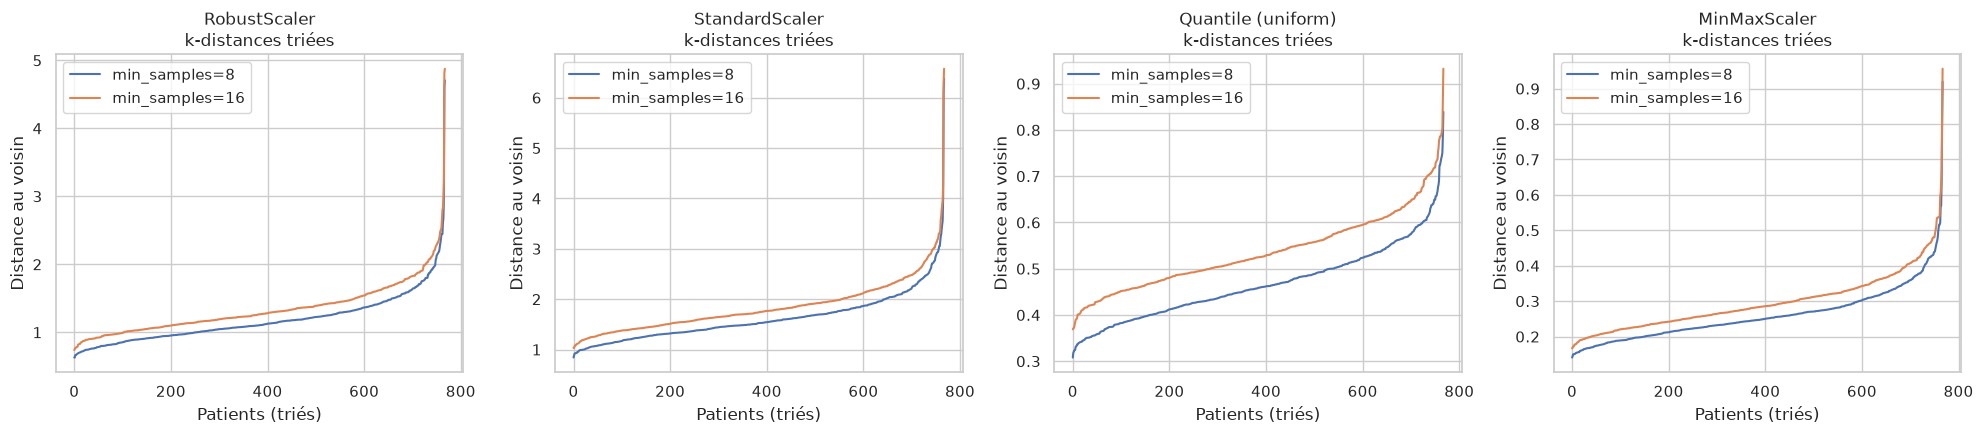

Valeurs de eps (percentiles des k-distances)


,scaler,min_samples,p50,p60,p70,p80,p85,p90,p95,p98
0,RobustScaler,8,1.104,1.183,1.264,1.387,1.479,1.589,1.800,2.150
1,RobustScaler,16,1.264,1.354,1.429,1.577,1.676,1.791,2.016,2.307
2,StandardScaler,8,1.526,1.626,1.738,1.896,2.029,2.155,2.469,2.910
3,StandardScaler,16,1.739,1.848,1.965,2.170,2.277,2.444,2.764,3.134
4,Quantile (uniform),8,0.458,0.479,0.500,0.529,0.547,0.569,0.604,0.657
5,Quantile (uniform),16,0.525,0.548,0.572,0.601,0.613,0.639,0.694,0.730
6,MinMaxScaler,8,0.247,0.262,0.278,0.309,0.325,0.352,0.397,0.445
7,MinMaxScaler,16,0.283,0.300,0.321,0.347,0.368,0.397,0.446,0.494


In [22]:
DBSCAN_SCALERS = ["RobustScaler", "StandardScaler", "Quantile (uniform)", "MinMaxScaler"]
MIN_SAMPLES_LIST = [8, 16]
PERCENTILES = [50, 60, 70, 80, 85, 90, 95, 98]


def k_distances(X: np.ndarray, min_samples: int) -> np.ndarray:
    nn = NearestNeighbors(n_neighbors=min_samples).fit(X)
    distances, _ = nn.kneighbors(X)
    return np.sort(distances[:, -1])


fig, axes = plt.subplots(1, len(DBSCAN_SCALERS), figsize=(20, 4.5))
eps_rows = []

for ax, scaler_name in zip(axes, DBSCAN_SCALERS):
    X_scaled = scale_data(X_model, scaler_name)
    for ms in MIN_SAMPLES_LIST:
        kd = k_distances(X_scaled, ms)
        ax.plot(kd, label=f"min_samples={ms}")
        eps_rows.append({
            "scaler": scaler_name, "min_samples": ms,
            **{f"p{p}": np.percentile(kd, p) for p in PERCENTILES},
        })
    ax.set_title(f"{scaler_name}\nk-distances triées")
    ax.set_xlabel("Patients (triés)")
    ax.set_ylabel("Distance au voisin")
    ax.legend()

plt.tight_layout()
plt.show()

print("Valeurs de eps (percentiles des k-distances)")
display(pd.DataFrame(eps_rows).round(3))

### 15.3 Grille de eps
Comme chaque scaler a sa propre échelle, nous définissons `eps` comme un **percentile** des k-distances (50 % à 98 %). Le percentile 90 % veut dire « 90 % des patients ont au moins `min_samples` voisins dans ce rayon ».

Deux valeurs de `min_samples` : **8** (règle usuelle `2 × dimensions` = 16 est aussi testée) et **16**.

Pour chaque combinaison, nous mesurons :
- le nombre de clusters (hors bruit) ;
- le **% de bruit** : part des patients non classés ;
- le **% du plus grand cluster** : un cluster à 95 % + du bruit n'est pas un vrai découpage ;
- silhouette et η² (calculés **hors bruit**).

Critères d'éligibilité : au moins **2 clusters**, bruit ≤ **20 %**, plus grand cluster ≤ **90 %** des patients classés.

In [23]:
dbscan_rows = []

for scaler_name in DBSCAN_SCALERS:
    X_scaled = scale_data(X_model, scaler_name)

    for ms in MIN_SAMPLES_LIST:
        kd = k_distances(X_scaled, ms)

        for p in PERCENTILES:
            eps = float(np.percentile(kd, p))
            labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
            metrics = evaluate_clustering(X_scaled, labels)

            valid = labels != -1
            eta_metabo = eta_demo = np.nan
            if metrics["n_clusters"] >= 2:
                etas = {c: eta_squared(df_clean.loc[valid, c], labels[valid])
                        for c in FEATURES}
                eta_metabo = np.mean([etas[c] for c in METABO_VARS])
                eta_demo = np.mean([etas[c] for c in DEMO_VARS])

            dbscan_rows.append({
                "scaler": scaler_name,
                "min_samples": ms,
                "percentile": p,
                "eps": eps,
                "n_clusters": metrics["n_clusters"],
                "noise_%": metrics["noise_pct"],
                "max_cluster_%": metrics["max_cluster_pct"],
                "min_cluster_%": metrics["min_cluster_pct"],
                "silhouette": metrics["silhouette"],
                "eta_metabo": eta_metabo,
                "eta_demo": eta_demo,
            })

dbscan_df = pd.DataFrame(dbscan_rows)
dbscan_df["ecart_metabo"] = dbscan_df["eta_metabo"] - dbscan_df["eta_demo"]
dbscan_df.to_csv(REPORTS_DIR / "dbscan_grid.csv", index=False)

for value, title in [("n_clusters", "Nombre de clusters"), ("noise_%", "% de bruit")]:
    print("=" * 70)
    print(f"{title} (min_samples = 16)")
    display(
        dbscan_df[dbscan_df["min_samples"] == 16]
        .pivot(index="scaler", columns="percentile", values=value)
        .round(1)
    )

dbscan_eligible = dbscan_df[
    (dbscan_df["n_clusters"] >= 2)
    & (dbscan_df["noise_%"] <= 20)
    & (dbscan_df["max_cluster_%"] <= 90)
]

print("=" * 70)
print(f"Éligibles : {len(dbscan_eligible)} lignes sur {len(dbscan_df)}")
display(
    dbscan_eligible.sort_values("eta_metabo", ascending=False)
    .head(10).round(3).reset_index(drop=True)
)

print("=" * 70)
print("Lignes avec >= 2 clusters (tous filtres levés), top 10 par silhouette")
display(
    dbscan_df[dbscan_df["n_clusters"] >= 2]
    .sort_values("silhouette", ascending=False)
    .head(10).round(3).reset_index(drop=True)
)

Nombre de clusters (min_samples = 16)


percentile,50,60,70,80,85,90,95,98
scaler,,,,,,,,
MinMaxScaler,1,1,1,1,1,1,1,1
Quantile (uniform),1,1,1,1,1,1,1,1
RobustScaler,1,1,1,1,1,1,1,1
StandardScaler,1,1,1,1,1,1,1,1


% de bruit (min_samples = 16)


percentile,50,60,70,80,85,90,95,98
scaler,,,,,,,,
MinMaxScaler,19.0,13.0,7.4,4.3,2.6,1.6,0.8,0.4
Quantile (uniform),8.7,4.3,2.5,0.9,0.4,0.1,0.0,0.0
RobustScaler,17.8,11.7,8.3,3.9,3.0,2.1,1.0,0.3
StandardScaler,17.8,12.6,7.3,3.9,2.9,2.0,1.2,0.3


Éligibles : 0 lignes sur 64


,scaler,min_samples,percentile,eps,n_clusters,noise_%,max_cluster_%,min_cluster_%,silhouette,eta_metabo,eta_demo,ecart_metabo


Lignes avec >= 2 clusters (tous filtres levés), top 10 par silhouette


,scaler,min_samples,percentile,eps,n_clusters,noise_%,max_cluster_%,min_cluster_%,silhouette,eta_metabo,eta_demo,ecart_metabo
0,Quantile (uniform),8,50,0.458,2,17.969,98.889,1.111,0.045,0.012,0.006,0.006


### 15.4 Décision pour DBSCAN

| Constat | Résultat |
|---|---|
| `min_samples = 16` | **1 seul cluster** pour les 32 combinaisons (4 scalers × 8 valeurs de eps) |
| Combinaisons avec ≥ 2 clusters | **1 sur 64** : Quantile (uniform), `min_samples = 8`, p50. Un cluster contient 98,9 % des patients classés, l'autre 1,1 % ; 18 % de bruit ; silhouette = 0,045 |
| Partitions éligibles (≥ 2 clusters, bruit ≤ 20 %, plus grand cluster ≤ 90 %) | **0** |
| % de bruit en fonction de eps | Décroissance **régulière** (ex. MinMax : 19 % → 0,4 %), sans plateau ni saut |

**Décision : DBSCAN est écarté comme modèle final.**

**Interprétation :** DBSCAN cherche des zones denses séparées par du vide. Ici il n'y a pas de vide : la densité des patients varie progressivement. Quel que soit eps, soit tous les patients forment un seul cluster, soit une poignée de patients est isolée.

**Usage retenu :** DBSCAN reste utile comme **détecteur de patients atypiques** (bruit à un eps élevé), pour documenter les profils isolés. Il ne sert pas à créer la colonne `Cluster`.

In [24]:
X_robust = scale_data(X_model, "RobustScaler")
kd = k_distances(X_robust, 16)
eps_outlier = float(np.percentile(kd, 98))

db_labels = DBSCAN(eps=eps_outlier, min_samples=16).fit_predict(X_robust)
atypical_idx = np.where(db_labels == -1)[0]

print(f"eps (p98, RobustScaler, min_samples=16) : {eps_outlier:.3f}")
print(f"Patients atypiques : {len(atypical_idx)} sur {len(df_clean)} "
      f"({len(atypical_idx) / len(df_clean) * 100:.2f} %)")

display(df_clean.iloc[atypical_idx].round(2))

eps (p98, RobustScaler, min_samples=16) : 2.307
Patients atypiques : 2 sur 768 (0.26 %)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
445,0.0,180.0,78.0,63.0,14.00,59.4,2.42,25.0
579,2.0,197.0,70.0,99.0,349.66,34.7,0.57,62.0


### 15.5 Bilan des quatre familles de modèles

Quatre familles indépendantes (centroïdes, probabiliste, hiérarchique, densité) convergent vers la même conclusion :

1. les patients forment un **continuum** et non des groupes naturellement séparés (silhouette ≈ 0,2, BIC sans minimum, pas de gap pour `single` et DBSCAN) ;
2. la seule partition stable et séparant selon le métabolisme est **k = 2** ;
3. K-Means avec RobustScaler fournit cette partition de la façon la plus stable et la plus simple.

> **Conséquence pour la suite du projet :** la colonne `Cluster` sera une **segmentation en deux profils (risque faible / élevé)** d'un continuum, ce qui correspond à la `risk_category` demandée. Elle ne représente pas une vérité biologique ; la classification supervisée de l'étape 5 apprendra à reproduire cette segmentation.

## 16. Analyse de stabilité et accord entre les finalistes

### 16.1 Finalistes
| Modèle | Configuration |
|---|---|
| **K-Means** | RobustScaler, k = 2 |
| **GMM** | Quantile (uniform), covariance `diag`, k = 2 |
| **Agglomératif (Ward)** | RobustScaler, k = 2 (référence visuelle uniquement, pour mesurer l'accord) |

### 16.2 Accord entre partitions
L'**ARI** (déjà défini en section 8) compare deux partitions des mêmes patients : 1 = identiques, ≈ 0 = indépendantes.

On calcule l'ARI entre chaque paire de modèles. Un ARI élevé (> 0,7) indique que les modèles trouvent **la même coupure** ; ce serait un argument de robustesse : le choix du modèle importerait peu.

On calcule aussi la **table de contingence** : combien de patients sont dans chaque couple de clusters.

In [25]:
def relabel_by_glucose(labels):
    order = df_clean.groupby(labels)["Glucose"].mean().sort_values().index
    mapping = {old: new for new, old in enumerate(order)}
    return np.array([mapping[l] for l in labels])


X_rob = scale_data(X_model, "RobustScaler")
X_qu = scale_data(X_model, "Quantile (uniform)")

final_labels = {
    "KMeans | Robust | k=2": relabel_by_glucose(make_model("KMeans", 2).fit_predict(X_rob)),
    "GMM | Quantile | diag | k=2": relabel_by_glucose(
        make_model("GMM", 2, covariance_type="diag").fit_predict(X_qu)),
    "Ward | Robust | k=2": relabel_by_glucose(
        make_model("Agglomerative", 2, linkage="ward").fit_predict(X_rob)),
}

names = list(final_labels)
ari_matrix = pd.DataFrame(
    [[adjusted_rand_score(final_labels[a], final_labels[b]) for b in names] for a in names],
    index=names, columns=names,
)
print("ARI entre les partitions")
display(ari_matrix.round(3))

for a, b in [(names[0], names[1]), (names[0], names[2])]:
    print("=" * 70)
    print(f"Table de contingence : {a} (lignes) vs {b} (colonnes)")
    display(pd.crosstab(final_labels[a], final_labels[b]))

print("=" * 70)
print("Taille et profil clinique (unités d'origine) des 3 partitions")
for name, labels in final_labels.items():
    prof = df_clean.groupby(labels)[["Glucose", "BMI", "DiabetesPedigreeFunction",
                                    "Pregnancies", "Age"]].mean()
    prof.insert(0, "taille_%", pd.Series(labels).value_counts(normalize=True).sort_index() * 100)
    print(name)
    display(prof.round(2))

ARI entre les partitions


,KMeans | Robust | k=2,GMM | Quantile | diag | k=2,Ward | Robust | k=2
KMeans | Robust | k=2,1.000,0.527,0.505
GMM | Quantile | diag | k=2,0.527,1.000,0.458
Ward | Robust | k=2,0.505,0.458,1.000


Table de contingence : KMeans | Robust | k=2 (lignes) vs GMM | Quantile | diag | k=2 (colonnes)


col_0,0,1
row_0,,
0,290,87
1,18,373


Table de contingence : KMeans | Robust | k=2 (lignes) vs Ward | Robust | k=2 (colonnes)


...

,taille_%,Glucose,BMI,DiabetesPedigreeFunction,Pregnancies,Age
0,49.09,102.72,28.78,0.42,2.78,28.25
1,50.91,139.89,35.97,0.52,4.87,38.05


GMM | Quantile | diag | k=2


,taille_%,Glucose,BMI,DiabetesPedigreeFunction,Pregnancies,Age
0,40.1,95.77,29.55,0.42,2.86,27.90
1,59.9,138.97,34.38,0.51,4.50,36.82


Ward | Robust | k=2


,taille_%,Glucose,BMI,DiabetesPedigreeFunction,Pregnancies,Age
0,51.3,103.06,30.22,0.44,2.55,26.80
1,48.7,141.22,34.79,0.50,5.21,40.02


### 16.3 Stabilité par bootstrap
- **Bootstrap :** on tire 768 patients **avec remise** dans le dataset (certains apparaissent plusieurs fois, d'autres jamais), on réentraîne le modèle, puis on affecte les 768 patients d'origine au centroïde le plus proche.
- **Mesure :** pour chaque patient, la **fréquence** avec laquelle il reçoit la même étiquette que dans le modèle de référence, sur 100 tirages. On aligne les numéros de clusters sur la référence avant de comparer (les numéros sont arbitraires).
- **Exemple :** un patient classé 1 dans 97 tirages sur 100 a une stabilité individuelle de 0,97. Un patient classé 1 dans 55 tirages et 0 dans 45 est **instable** (proche de la frontière).
- **À quoi ça sert ?** Repérer la **zone frontière** : les patients dont l'étiquette dépend de l'échantillon. Ces patients seront les plus difficiles pour le classifieur supervisé de l'étape 5.

Seuil retenu : un patient est **instable** si sa fréquence d'étiquette stable est < 0,90.

KMeans | Robust | k=2
Stabilité individuelle moyenne : 0.957
Patients instables (< 0,90)    : 107 (13.9 %)
GMM | Quantile | diag | k=2
Stabilité individuelle moyenne : 0.931
Patients instables (< 0,90)    : 179 (23.3 %)


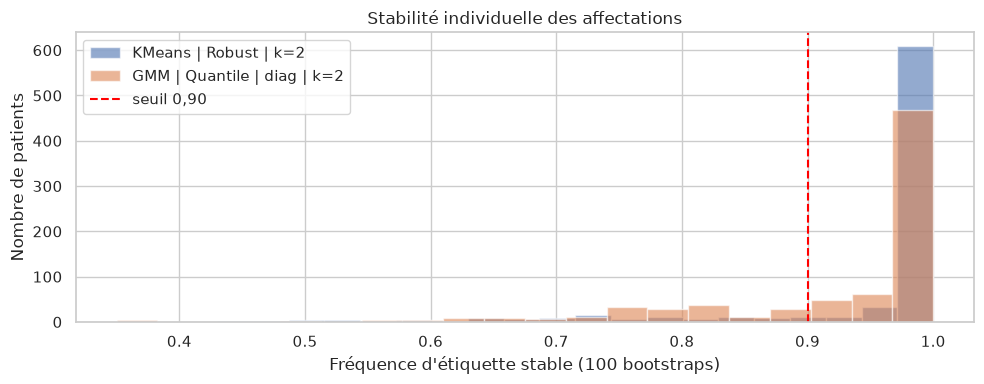

Profil moyen : patients instables vs stables (K-Means, unités d'origine)


,instables,stables
Pregnancies,4.00,3.82
Glucose,119.60,121.97
BloodPressure,70.18,72.70
SkinThickness,30.43,28.66
Insulin,141.09,154.57
BMI,33.02,32.35
DiabetesPedigreeFunction,0.46,0.47
Age,34.80,32.99


In [26]:
def bootstrap_patient_stability(X, model_name, k, reference_labels, n_boot=100,
                                seed=RANDOM_STATE, **params):
    rng = np.random.RandomState(seed)
    n = X.shape[0]
    agree = np.zeros(n)

    for _ in range(n_boot):
        idx = rng.choice(n, n, replace=True)
        model = make_model(model_name, k, **params).fit(X[idx])
        pred = model.predict(X)

        same = (pred == reference_labels).mean()
        if same < 0.5:
            pred = 1 - pred
        agree += (pred == reference_labels)

    return agree / n_boot


boot_results = {}
configs = [
    ("KMeans | Robust | k=2", "KMeans", X_rob, {}),
    ("GMM | Quantile | diag | k=2", "GMM", X_qu, {"covariance_type": "diag"}),
]

for name, model_name, X_scaled, params in configs:
    ref = final_labels[name]
    freq = bootstrap_patient_stability(X_scaled, model_name, 2, ref, **params)
    boot_results[name] = freq

    unstable = (freq < 0.90)
    print("=" * 70)
    print(name)
    print(f"Stabilité individuelle moyenne : {freq.mean():.3f}")
    print(f"Patients instables (< 0,90)    : {unstable.sum()} "
          f"({unstable.mean() * 100:.1f} %)")

fig, ax = plt.subplots(figsize=(10, 4))
for name, freq in boot_results.items():
    ax.hist(freq, bins=20, alpha=0.6, label=name)
ax.axvline(0.90, color="red", linestyle="--", label="seuil 0,90")
ax.set_xlabel("Fréquence d'étiquette stable (100 bootstraps)")
ax.set_ylabel("Nombre de patients")
ax.set_title("Stabilité individuelle des affectations")
ax.legend()
plt.tight_layout()
plt.show()

unstable_km = boot_results["KMeans | Robust | k=2"] < 0.90
print("Profil moyen : patients instables vs stables (K-Means, unités d'origine)")
display(pd.DataFrame({
    "instables": df_clean[unstable_km].mean(),
    "stables": df_clean[~unstable_km].mean(),
}).round(2))

### 16.4 Bilan de l'analyse de stabilité

**Accord entre modèles.** Les trois partitions (K-Means, GMM, Ward) séparent les patients dans le même sens (glycémie ≈ 100 contre ≈ 140), mais le **seuil de coupure diffère** : ARI entre 0,46 et 0,53, soit 105 à 111 patients classés différemment (≈ 14 %). Sur un continuum, la frontière peut être placée à plusieurs endroits : la colonne `Cluster` dépend donc en partie du **choix du modèle**.

**Stabilité par bootstrap.**
| Modèle | Stabilité individuelle moyenne | Patients instables (< 0,90) |
|---|---|---|
| K-Means (RobustScaler) | **0,957** | **107 (13,9 %)** |
| GMM (Quantile, diag) | 0,931 | 179 (23,3 %) |

> Précision : le scaler est ajusté une fois sur tous les patients et non réajusté à chaque bootstrap. La mesure porte sur l'étape de clustering seule ; elle est légèrement optimiste, de la même façon pour les deux modèles.

**Zone frontière.** Les patients instables ont des profils proches de la moyenne globale (Glucose ≈ 120, BMI ≈ 33). Ils forment la zone de transition entre les deux profils et seront les plus difficiles à classer à l'étape 5.

## 17. Comparaison globale et choix du modèle final

Nous rassemblons dans un seul tableau les résultats des étapes précédentes.

In [27]:
def summarize(name, labels, X_scaled, stab_ari, extra):
    etas = {c: eta_squared(df_clean[c], labels) for c in FEATURES}
    sizes = pd.Series(labels).value_counts(normalize=True) * 100
    return {
        "modèle": name,
        "silhouette": silhouette_score(X_scaled, labels),
        "davies_bouldin": davies_bouldin_score(X_scaled, labels),
        "min_cluster_%": sizes.min(),
        "eta_metabo": np.mean([etas[c] for c in METABO_VARS]),
        "eta_demo": np.mean([etas[c] for c in DEMO_VARS]),
        "ARI_resampling": stab_ari,
        **extra,
    }

comparison = pd.DataFrame([
    summarize("K-Means | Robust | k=2", final_labels["KMeans | Robust | k=2"], X_rob,
            0.883, {"stabilité_bootstrap": boot_results["KMeans | Robust | k=2"].mean(),
                      "instables_%": (boot_results["KMeans | Robust | k=2"] < 0.9).mean() * 100}),
    summarize("GMM | Quantile | diag | k=2", final_labels["GMM | Quantile | diag | k=2"], X_qu,
            0.801, {"stabilité_bootstrap": boot_results["GMM | Quantile | diag | k=2"].mean(),
                      "instables_%": (boot_results["GMM | Quantile | diag | k=2"] < 0.9).mean() * 100}),
]).set_index("modèle")
comparison["ecart_metabo"] = comparison["eta_metabo"] - comparison["eta_demo"]

display(comparison.round(3))
comparison.to_csv(REPORTS_DIR / "clustering_final_comparison.csv")

rejected = pd.DataFrame({
    "modèle": ["Agglomératif (toutes liaisons)", "DBSCAN (toutes grilles)"],
    "raison du rejet": [
        "0 partition avec cluster min ≥ 5 % et ARI ≥ 0,50 ; single isole 1 patient",
        "1 seul cluster pour min_samples = 16 ; 1 partition à 2 clusters (98,9 % / 1,1 %)",
    ],
}).set_index("modèle")
display(rejected)

,silhouette,davies_bouldin,min_cluster_%,eta_metabo,eta_demo,ARI_resampling,stabilité_bootstrap,instables_%,ecart_metabo
modèle,,,,,,,,,
K-Means | Robust | k=2,0.203,1.733,49.089,0.235,0.135,0.883,0.957,13.932,0.100
GMM | Quantile | diag | k=2,0.201,1.776,40.104,0.201,0.098,0.801,0.931,23.307,0.104


,raison du rejet
modèle,
Agglomératif (toutes liaisons),"0 partition avec cluster min ≥ 5 % et ARI ≥ 0,..."
DBSCAN (toutes grilles),1 seul cluster pour min_samples = 16 ; 1 parti...


### 17.1 Modèle retenu

| Élément | Décision provisoire |
|---|---|
| Modèle | **K-Means** |
| Scaler | **RobustScaler** |
| Nombre de clusters | **k = 2** (à revérifier après la sélection de variables, section 19) |

Le K-Means est **nettement meilleur sur la stabilité** (bootstrap 0,957 contre 0,931 ; 13,9 % de patients instables contre 23,3 %) et légèrement meilleur sur `eta_metabo` (0,235 contre 0,201) et Davies-Bouldin. Le GMM est équivalent sur la silhouette (0,201 contre 0,203) et sur `ecart_metabo` (0,104 contre 0,100). Aucun modèle ne domine nettement K-Means.

K-Means offre en plus des centroïdes et une méthode `predict`, ce qui simplifie MLflow et le pipeline.

## 18. Test de sous-ensembles de variables

### 18.1 Pourquoi tester ?
Le projet demande de « sélectionner les variables présentant la plus grande variabilité ». Une comparaison des variances brutes est trompeuse (Glucose pèse 76 % de la variance totale simplement à cause de son unité). Nous testons donc **empiriquement** si retirer des variables améliore ou dégrade le clustering.

### 18.2 Sous-ensembles comparés
| Sous-ensemble | Variables |
|---|---|
| Toutes | les 8 variables |
| Sans DPF | 7 variables (DPF sépare presque rien : η² ≤ 0,02) |
| Top 5 η² | les 5 variables avec le plus grand η² dans la partition actuelle |
| Noyau métabolique | Glucose, Insulin, BMI, SkinThickness, BloodPressure |

### 18.3 Comment juger
- **ARI avec la partition complète** : proche de 1 = le sous-ensemble reproduit la même coupure, les variables retirées n'apportaient rien.
- **Stabilité (ARI par rééchantillonnage)**.
- **η² métabolique et démographique**.
- ⚠️ La **silhouette ne peut pas servir de critère** : elle augmente mécaniquement quand on retire des dimensions.
- ⚠️ Classer les variables par η² de la partition actuelle est **partiellement circulaire** : ce sont les variables qui expliquent déjà la partition obtenue.

In [28]:
ref_labels = final_labels["KMeans | Robust | k=2"]

eta_full = pd.Series({c: eta_squared(df_clean[c], ref_labels) for c in FEATURES})
print("η² par variable (partition K-Means complète)")
display(eta_full.sort_values(ascending=False).round(3).to_frame("eta2"))

SUBSETS = {
    "Toutes (8)": FEATURES,
    "Sans DPF (7)": [c for c in FEATURES if c != "DiabetesPedigreeFunction"],
    "Top 5 η²": eta_full.sort_values(ascending=False).head(5).index.tolist(),
    "Noyau métabolique (5)": ["Glucose", "Insulin", "BMI", "SkinThickness", "BloodPressure"],
}

subset_rows = []
for name, cols in SUBSETS.items():
    Xs = RobustScaler().fit_transform(X_model[cols])
    labels = relabel_by_glucose(make_model("KMeans", 2).fit_predict(Xs))
    stab_mean, stab_std = stability_score(Xs, "KMeans", 2, n_repeats=30)
    etas = {c: eta_squared(df_clean[c], labels) for c in FEATURES}

    subset_rows.append({
        "sous-ensemble": name,
        "n_vars": len(cols),
        "ARI_vs_complet": adjusted_rand_score(ref_labels, labels),
        "stabilité_ARI": stab_mean,
        "±": stab_std,
        "min_cluster_%": pd.Series(labels).value_counts(normalize=True).min() * 100,
        "eta_metabo": np.mean([etas[c] for c in METABO_VARS]),
        "eta_demo": np.mean([etas[c] for c in DEMO_VARS]),
        "silhouette (info)": silhouette_score(Xs, labels),
    })

subset_df = pd.DataFrame(subset_rows).set_index("sous-ensemble")
subset_df["ecart_metabo"] = subset_df["eta_metabo"] - subset_df["eta_demo"]
display(subset_df.round(3))
subset_df.to_csv(REPORTS_DIR / "kmeans_feature_subsets.csv")

η² par variable (partition K-Means complète)


,eta2
Glucose,0.372
Insulin,0.282
SkinThickness,0.278
BMI,0.274
BloodPressure,0.180
Age,0.174
Pregnancies,0.096
DiabetesPedigreeFunction,0.021


,n_vars,ARI_vs_complet,stabilité_ARI,±,min_cluster_%,eta_metabo,eta_demo,silhouette (info),ecart_metabo
sous-ensemble,,,,,,,,,
Toutes (8),8,1.000,0.883,0.080,49.089,0.235,0.135,0.203,0.100
Sans DPF (7),7,0.893,0.874,0.079,48.958,0.230,0.156,0.230,0.074
Top 5 η²,5,0.707,0.929,0.058,49.740,0.249,0.044,0.269,0.206
Noyau métabolique (5),5,0.707,0.929,0.058,49.740,0.249,0.044,0.269,0.206


### 18.4 Décision sur la sélection de variables

| Constat | Résultat |
|---|---|
| Top 5 par η² | Glucose, Insulin, SkinThickness, BMI, BloodPressure : **identique** au noyau métabolique défini a priori |
| Stabilité (ARI) | 0,929 ± 0,058 avec 5 variables, contre 0,883 ± 0,080 avec 8 : au moins équivalente |
| `eta_demo` | 0,044 contre 0,135 : la séparation n'est plus portée par Age et Pregnancies |
| ARI avec la partition à 8 variables | 0,707 : même sens, mais ≈ 12 à 15 % des patients changent de groupe |

**Décision :** le clustering utilise le **noyau métabolique (5 variables)**.

- **Sélection par pouvoir de séparation (η²), pas par variance brute** : la variance brute dépend des unités (Glucose pèse 76 % de la variance uniquement à cause de son échelle).
- **Pregnancies, Age et DPF** restent dans le dataset pour l'interprétation des clusters et seront candidats pour la classification supervisée.

> **Limites :**
> - Une partie du gain de `ecart_metabo` est mécanique (Pregnancies et Age ne participent plus au clustering).
> - Le `Cluster` final dépend en partie du choix des variables (ARI 0,707 avec la partition à 8 variables).
> - Le k et le scaler ont été choisis sur 8 variables : ils sont revérifiés à la section 19.

## 19. Vérification de k et du scaler sur le noyau métabolique

Le scaler et k ont été choisis avec les 8 variables, dont Age et Pregnancies qui dominaient la variance. Avec 5 variables, la géométrie change : nous refaisons la comparaison.

Pour chaque scaler et chaque k de 2 à 5, nous mesurons :

- **variance expliquée** et **baisse relative de l'inertie** (coude, définis en 12.2) ;
- **silhouette** et **stabilité ARI** ;
- **`eta_core`** : moyenne de η² sur les 5 variables utilisées ;
- **`eta_profil`** : moyenne de η² sur Pregnancies, Age et DPF (non utilisées pour le clustering). **Qu'est-ce que c'est ?** Un clustering métabolique « honnête » doit aussi séparer un peu ces variables (elles sont corrélées au métabolisme), mais pas être dominé par elles ;
- **ARI avec la partition actuelle (8 variables, RobustScaler, k=2)** : mesure combien de patients changent de groupe.

Seuls les partitions avec un plus petit cluster ≥ 5 % sont retenues pour la lecture.

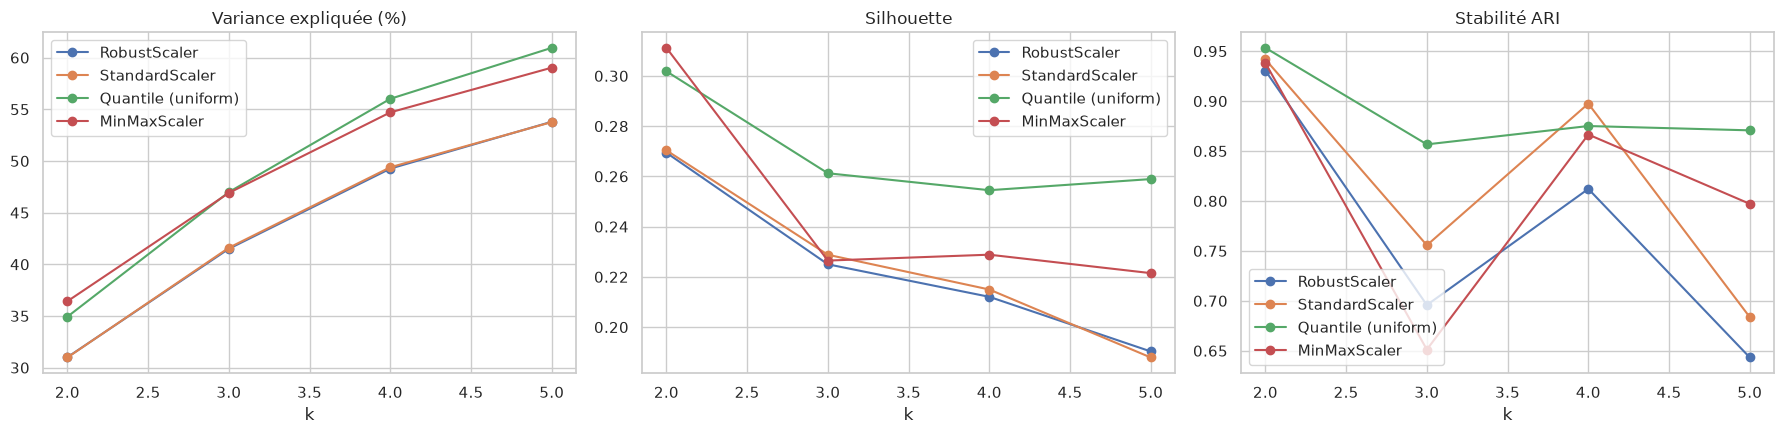

K-Means (5 variables) | RobustScaler


,k,variance_expliquee_%,baisse_relative_%,silhouette,stabilité_ARI,±,min_cluster_%,eta_core,eta_profil,ARI_vs_8vars
0,2,31.009,31.009,0.269,0.931,0.060,49.740,0.297,0.033,0.707
1,3,41.505,15.214,0.225,0.696,0.170,26.432,0.392,0.040,NaN
2,4,49.260,13.258,0.212,0.812,0.124,16.536,0.475,0.054,NaN
3,5,53.796,8.939,0.190,0.643,0.135,13.281,0.512,0.052,NaN


K-Means (5 variables) | StandardScaler


,k,variance_expliquee_%,baisse_relative_%,silhouette,stabilité_ARI,±,min_cluster_%,eta_core,eta_profil,ARI_vs_8vars
0,2,30.983,30.983,0.270,0.942,0.050,48.568,0.299,0.032,0.694
1,3,41.602,15.386,0.229,0.756,0.171,26.953,0.396,0.039,NaN
2,4,49.392,13.339,0.215,0.897,0.092,16.927,0.481,0.049,NaN
3,5,53.764,8.639,0.188,0.684,0.183,14.062,0.519,0.054,NaN


K-Means (5 variables) | Quantile (uniform)


,k,variance_expliquee_%,baisse_relative_%,silhouette,stabilité_ARI,±,min_cluster_%,eta_core,eta_profil,ARI_vs_8vars
0,2,34.929,34.929,0.302,0.953,0.036,48.568,0.293,0.036,0.685
1,3,46.990,18.536,0.261,0.857,0.222,23.177,0.393,0.035,NaN
2,4,56.017,17.028,0.254,0.875,0.055,22.266,0.465,0.059,NaN
3,5,60.951,11.217,0.259,0.871,0.070,16.406,0.501,0.073,NaN


K-Means (5 variables) | MinMaxScaler


,k,variance_expliquee_%,baisse_relative_%,silhouette,stabilité_ARI,±,min_cluster_%,eta_core,eta_profil,ARI_vs_8vars
0,2,36.426,36.426,0.311,0.938,0.052,43.229,0.271,0.032,0.468
1,3,46.909,16.490,0.226,0.651,0.211,24.089,0.353,0.053,NaN
2,4,54.705,14.684,0.229,0.867,0.058,21.615,0.454,0.050,NaN
3,5,59.031,9.551,0.221,0.797,0.082,12.760,0.504,0.053,NaN


In [29]:
CORE = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
PROFILE_VARS = ["Pregnancies", "Age", "DiabetesPedigreeFunction"]
CORE_SCALERS = ["RobustScaler", "StandardScaler", "Quantile (uniform)", "MinMaxScaler"]
CORE_K = range(2, 6)

X_core = X_model[CORE].copy()
ref_8vars = final_labels["KMeans | Robust | k=2"]

core_rows = []

for scaler_name in CORE_SCALERS:
    Xs = clone(SCALERS[scaler_name]).fit_transform(X_core)
    total_inertia = ((Xs - Xs.mean(axis=0)) ** 2).sum()
    previous = total_inertia

    for k in CORE_K:
        model = make_model("KMeans", k)
        labels = model.fit_predict(Xs)
        etas = {c: eta_squared(df_clean[c], labels) for c in FEATURES}
        stab_mean, stab_std = stability_score(Xs, "KMeans", k, n_repeats=20)

        core_rows.append({
            "scaler": scaler_name,
            "k": k,
            "variance_expliquee_%": (1 - model.inertia_ / total_inertia) * 100,
            "baisse_relative_%": (1 - model.inertia_ / previous) * 100,
            "silhouette": silhouette_score(Xs, labels),
            "stabilité_ARI": stab_mean,
            "±": stab_std,
            "min_cluster_%": pd.Series(labels).value_counts(normalize=True).min() * 100,
            "eta_core": np.mean([etas[c] for c in CORE]),
            "eta_profil": np.mean([etas[c] for c in PROFILE_VARS]),
            "ARI_vs_8vars": adjusted_rand_score(ref_8vars, labels) if k == 2 else np.nan,
        })
        previous = model.inertia_

core_df = pd.DataFrame(core_rows)
core_df.to_csv(REPORTS_DIR / "kmeans_core_recheck.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for scaler_name in CORE_SCALERS:
    sub = core_df[core_df["scaler"] == scaler_name]
    axes[0].plot(sub["k"], sub["variance_expliquee_%"], marker="o", label=scaler_name)
    axes[1].plot(sub["k"], sub["silhouette"], marker="o", label=scaler_name)
    axes[2].plot(sub["k"], sub["stabilité_ARI"], marker="o", label=scaler_name)

axes[0].set_title("Variance expliquée (%)")
axes[1].set_title("Silhouette")
axes[2].set_title("Stabilité ARI")
for ax in axes:
    ax.set_xlabel("k")
    ax.legend()
plt.tight_layout()
plt.show()

for scaler_name in CORE_SCALERS:
    print("=" * 70)
    print(f"K-Means (5 variables) | {scaler_name}")
    display(
        core_df[core_df["scaler"] == scaler_name]
        .drop(columns="scaler")
        .round(3)
        .reset_index(drop=True)
    )

In [30]:
Xs = RobustScaler().fit_transform(X_core)
labels_core = relabel_by_glucose(make_model("KMeans", 2).fit_predict(Xs))

prof = df_clean.groupby(labels_core).mean()
prof.insert(0, "taille_%", pd.Series(labels_core).value_counts(normalize=True).sort_index() * 100)
prof["criteres_depasses"] = (
    (prof["Glucose"] > 126).astype(int)
    + (prof["BMI"] > 30).astype(int)
    + (prof["DiabetesPedigreeFunction"] > 0.5).astype(int)
)
print("K-Means | RobustScaler | 5 variables | k=2")
display(prof.round(2))

print("Patients qui changent de groupe (8 variables → 5 variables)")
display(pd.crosstab(
    pd.Series(ref_8vars, name="8 variables"),
    pd.Series(labels_core, name="5 variables"),
))

K-Means | RobustScaler | 5 variables | k=2


,taille_%,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,criteres_depasses
0,49.74,3.37,103.33,67.87,23.37,100.37,28.24,0.44,30.16,0
1,50.26,4.31,139.77,76.79,34.39,204.48,36.60,0.51,36.29,3


Patients qui changent de groupe (8 variables → 5 variables)


5 variables,0,1
8 variables,,
0,349,28
1,33,358


## 20. Entraînement final du modèle et ajout de `Cluster`

Les expériences précédentes ont permis de sélectionner la configuration finale :

* **Algorithme :** K-Means
* **Nombre de clusters :** `k = 2`
* **Scaler :** `RobustScaler`
* **Variables utilisées pour le clustering :**

  * `Glucose`
  * `BloodPressure`
  * `SkinThickness`
  * `Insulin`
  * `BMI`

Les variables `Pregnancies`, `Age` et `DiabetesPedigreeFunction` restent présentes dans le dataset, mais elles ne participent pas au calcul des clusters.

### Pourquoi cette configuration ?

`RobustScaler` a été retenu car il est moins sensible aux valeurs extrêmes que les scalers basés sur la moyenne et l'écart-type.

Le choix de `k = 2` est cohérent avec les résultats obtenus sur le noyau métabolique :

* meilleure stabilité parmi les valeurs testées ;
* silhouette supérieure aux valeurs de `k > 2` ;
* deux groupes de tailles équilibrées ;
* séparation principalement portée par les variables métaboliques ;
* correspondance avec l'objectif métier de distinguer deux profils.

### Attention à l'étiquette des clusters

Les numéros produits par K-Means sont arbitraires. Pour obtenir une convention stable et interprétable, nous renumérottons les clusters selon leur glycémie moyenne :

* `Cluster 0` → profil ayant la plus faible glycémie moyenne ;
* `Cluster 1` → profil ayant la plus forte glycémie moyenne.

Cette étape ne modifie pas les patients regroupés ensemble : elle ne fait que changer les numéros des groupes.

Enfin, nous ajoutons la colonne `Cluster` au dataset clinique original `df_clean`, qui servira ensuite à l'analyse des profils et à la classification supervisée.


### 20.1 Préparation des données finales

In [31]:
FINAL_MODEL_NAME = "KMeans"
FINAL_SCALER_NAME = "RobustScaler"
FINAL_K = 2

FINAL_FEATURES = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
]

X_final = X_model[FINAL_FEATURES].copy()

assert X_final.shape[0] == df_clean.shape[0]
assert X_final.isna().sum().sum() == 0
assert np.isfinite(X_final.to_numpy()).all()

print("Variables utilisées pour le clustering final :")
print(FINAL_FEATURES)
print()
print(f"Nombre de patients : {len(X_final)}")
print(f"Nombre de variables : {X_final.shape[1]}")

Variables utilisées pour le clustering final :
['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

Nombre de patients : 768
Nombre de variables : 5


### 20.2 Ajustement du scaler final

In [32]:
final_scaler = RobustScaler()

X_final_scaled = final_scaler.fit_transform(X_final)

assert X_final_scaled.shape == X_final.shape
assert np.isfinite(X_final_scaled).all()

print("\n✅ RobustScaler ajusté sur les données finales.")


✅ RobustScaler ajusté sur les données finales.


### 20.3 Entraînement du K-Means final

In [33]:
final_kmeans = KMeans(
    n_clusters=FINAL_K,
    n_init=10,
    random_state=RANDOM_STATE,
)

raw_labels = final_kmeans.fit_predict(X_final_scaled)

assert len(raw_labels) == len(df_clean)

print("\n✅ K-Means final entraîné.")
print(f"k = {FINAL_K}")
print(f"Inertie finale : {final_kmeans.inertia_:.3f}")


✅ K-Means final entraîné.
k = 2
Inertie finale : 1545.416


### 20.4 Renumérotation des clusters par glycémie moyenne

In [34]:
cluster_glucose_means = (
    df_clean.groupby(raw_labels)["Glucose"]
    .mean()
    .sort_values()
)

cluster_mapping = {
    old_label: new_label
    for new_label, old_label in enumerate(cluster_glucose_means.index)
}

final_labels = np.array([
    cluster_mapping[label]
    for label in raw_labels
])

assert set(final_labels) == {0, 1}

print("\nConvention finale des clusters :")

for old_label, new_label in cluster_mapping.items():
    glucose_mean = cluster_glucose_means.loc[old_label]
    print(
        f"Ancien cluster {old_label} → Cluster {new_label} "
        f"(Glucose moyen = {glucose_mean:.2f})"
    )


Convention finale des clusters :
Ancien cluster 0 → Cluster 0 (Glucose moyen = 103.33)
Ancien cluster 1 → Cluster 1 (Glucose moyen = 139.77)


### 20.5 Création du dataset final avec la colonne Cluster

In [35]:
df_clustered = df_clean.copy()
df_clustered["Cluster"] = final_labels

assert df_clustered.shape[0] == df_clean.shape[0]
assert df_clustered["Cluster"].isna().sum() == 0
assert set(df_clustered["Cluster"].unique()) == {0, 1}

print("\n✅ Colonne 'Cluster' ajoutée au dataset.")


✅ Colonne 'Cluster' ajoutée au dataset.


### 20.6 Distribution des clusters

In [36]:
cluster_counts = (
    df_clustered["Cluster"]
    .value_counts()
    .sort_index()
    .rename("count")
)

cluster_distribution = pd.DataFrame({
    "count": cluster_counts,
    "percentage": cluster_counts / len(df_clustered) * 100,
})

print("\nDistribution des clusters :")
display(cluster_distribution.round(2))


Distribution des clusters :


,count,percentage
Cluster,,
0,382,49.74
1,386,50.26


### 20.7 Profil clinique initial de chaque cluster

In [37]:
cluster_profiles = (
    df_clustered
    .groupby("Cluster")[FEATURES]
    .mean()
)

cluster_profiles.insert(
    0,
    "count",
    df_clustered["Cluster"].value_counts().sort_index()
)

cluster_profiles.insert(
    1,
    "percentage",
    df_clustered["Cluster"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
)

print("\nProfil moyen de chaque cluster :")
display(cluster_profiles.round(2))


Profil moyen de chaque cluster :


,count,percentage,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
Cluster,,,,,,,,,,
0,382,49.74,3.37,103.33,67.87,23.37,100.37,28.24,0.44,30.16
1,386,50.26,4.31,139.77,76.79,34.39,204.48,36.60,0.51,36.29


### 20.8 Vérification de la convention des labels

In [38]:
assert (
    cluster_profiles.loc[0, "Glucose"]
    <= cluster_profiles.loc[1, "Glucose"]
)

print(
    "\n✅ Convention vérifiée : "
    "Cluster 0 possède la glycémie moyenne la plus faible "
    "et Cluster 1 la plus élevée."
)


✅ Convention vérifiée : Cluster 0 possède la glycémie moyenne la plus faible et Cluster 1 la plus élevée.


### 20.9 Aperçu du dataset final

In [39]:
display(df_clustered.head())

print(f"\nShape finale : {df_clustered.shape}")

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Cluster
0,6.0,148.0,72.0,35.00000,218.922936,33.6,0.627,50.0,1
1,1.0,85.0,66.0,29.00000,70.302990,26.6,0.351,31.0,0
2,8.0,183.0,64.0,21.53261,268.502273,23.3,0.672,32.0,1
3,1.0,89.0,66.0,23.00000,94.000000,28.1,0.167,21.0,0
4,0.0,137.0,40.0,35.00000,168.000000,43.1,2.288,33.0,1



Shape finale : (768, 9)


## 21. PCA et visualisation des clusters

Le clustering final utilise cinq variables et travaille donc dans un espace à cinq dimensions. Une visualisation directe de cet espace est impossible sur un graphique classique.

Nous utilisons **PCA (Principal Component Analysis)** uniquement pour représenter les patients dans un espace bidimensionnel.

PCA cherche de nouvelles directions appelées **composantes principales** :

* **PC1** est la direction qui explique le plus de variance ;
* **PC2** est la deuxième direction qui explique le plus de variance, sous contrainte d'être orthogonale à PC1.

Chaque patient est ensuite projeté sur ces deux axes afin d'obtenir une représentation 2D.

### Variance expliquée

Pour chaque composante, PCA fournit une `explained_variance_ratio_`.

Cette valeur représente la proportion de la variance totale des données expliquée par la composante.

Par exemple, si PC1 explique 35 % et PC2 25 %, la représentation 2D conserve environ 60 % de la variance totale.

Une valeur élevée signifie que la projection 2D représente relativement bien la structure originale. Une valeur faible indique que plusieurs informations importantes restent dans les dimensions suivantes.

### Objectifs de cette visualisation

Nous allons :

1. projeter les données finales standardisées par `RobustScaler` dans l'espace PCA ;
2. afficher les patients selon leur cluster ;
3. afficher les centroïdes des deux clusters dans le même espace PCA ;
4. mesurer la variance expliquée par PC1 et PC2 ;
5. visualiser la répartition des patients entre les deux clusters.

> **Important :** PCA n'est pas utilisé pour construire le clustering final. Il sert uniquement à visualiser les groupes déjà obtenus par K-Means.


### 21.1 Préparation des données pour PCA

In [40]:
X_pca_input = X_final_scaled.copy()

assert X_pca_input.shape == (len(df_clustered), len(FINAL_FEATURES))
assert np.isfinite(X_pca_input).all()

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_pca_input)

assert X_pca.shape == (len(df_clustered), 2)
assert np.isfinite(X_pca).all()

print("✅ PCA calculée.")
print(f"Forme des données PCA : {X_pca.shape}")

✅ PCA calculée.
Forme des données PCA : (768, 2)


### 21.2 Variance expliquée par les composantes principales

In [41]:
explained_variance = pd.Series(
    pca.explained_variance_ratio_,
    index=["PC1", "PC2"],
    name="variance_expliquee"
)

explained_variance_pct = explained_variance * 100

total_explained_variance = explained_variance.sum() * 100

print("\nVariance expliquée par les composantes :")
display(
    explained_variance_pct
    .to_frame("variance_expliquee_%")
    .round(2)
)

print(
    f"Variance totale expliquée par PC1 + PC2 : "
    f"{total_explained_variance:.2f} %"
)


Variance expliquée par les composantes :


,variance_expliquee_%
PC1,48.25
PC2,24.35


Variance totale expliquée par PC1 + PC2 : 72.60 %


### 21.3 Création du DataFrame PCA

In [42]:
pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Cluster": df_clustered["Cluster"].to_numpy(),
})

display(pca_df.head())

,PC1,PC2,Cluster
0,0.943380,0.390626,1
1,-1.257632,-0.426079,0
2,0.362660,2.087893,1
3,-1.128372,-0.040327,0
4,0.488316,0.021098,1


### 21.4 Projection des centroïdes K-Means dans l'espace PCA

In [43]:
centroids_pca = pca.transform(final_kmeans.cluster_centers_)

centroids_df = pd.DataFrame(
    centroids_pca,
    columns=["PC1", "PC2"],
    index=[0, 1],
)

centroids_df.index.name = "Cluster"

print("\nCentroïdes dans l'espace PCA :")
display(centroids_df.round(3))


Centroïdes dans l'espace PCA :


,PC1,PC2
Cluster,,
0,-0.955,0.032
1,0.945,-0.031


### 21.5 Visualisation 2D des clusters

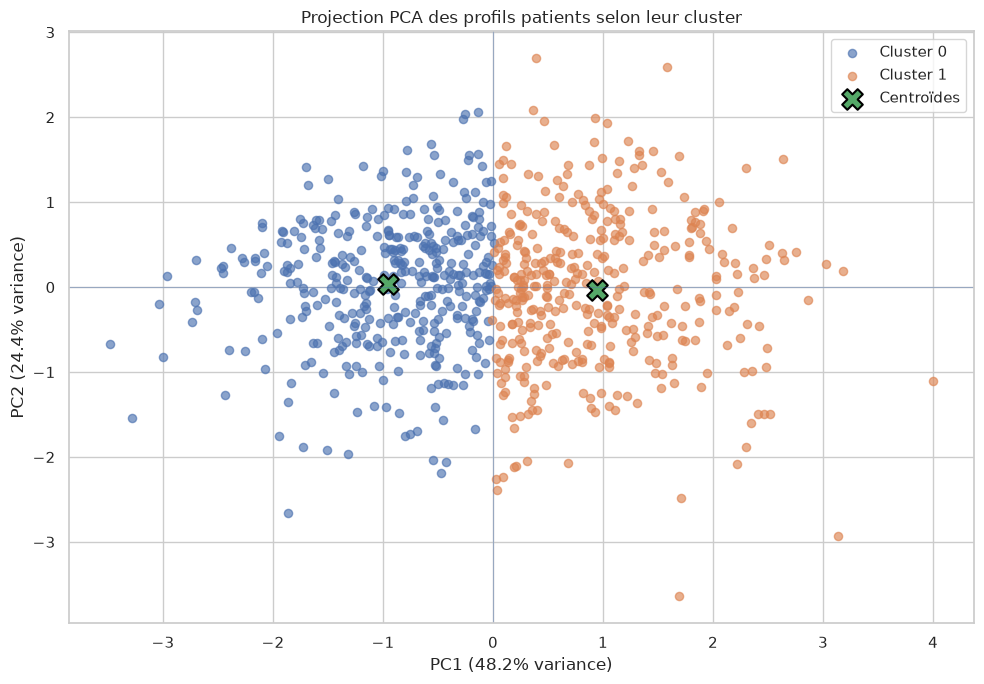

In [44]:
plt.figure(figsize=(10, 7))

for cluster_id in sorted(pca_df["Cluster"].unique()):
    cluster_data = pca_df[pca_df["Cluster"] == cluster_id]

    plt.scatter(
        cluster_data["PC1"],
        cluster_data["PC2"],
        s=35,
        alpha=0.65,
        label=f"Cluster {cluster_id}",
    )
    
plt.scatter(
    centroids_df["PC1"],
    centroids_df["PC2"],
    marker="X",
    s=220,
    edgecolor="black",
    linewidth=1.5,
    label="Centroïdes",
)

plt.axhline(0, linewidth=0.8, alpha=0.4)
plt.axvline(0, linewidth=0.8, alpha=0.4)

plt.xlabel(
    f"PC1 ({explained_variance_pct['PC1']:.1f}% variance)"
)

plt.ylabel(
    f"PC2 ({explained_variance_pct['PC2']:.1f}% variance)"
)

plt.title("Projection PCA des profils patients selon leur cluster")
plt.legend()
plt.tight_layout()
plt.show()

### 21.6 Répartition des observations par cluster

In [45]:
cluster_distribution = (
    df_clustered["Cluster"]
    .value_counts()
    .sort_index()
    .to_frame("count")
)

cluster_distribution["percentage"] = (
    cluster_distribution["count"]
    / len(df_clustered)
    * 100
)

print("\nRépartition des observations par cluster :")
display(cluster_distribution.round(2))


Répartition des observations par cluster :


,count,percentage
Cluster,,
0,382,49.74
1,386,50.26


### 21.7 Visualisation de la taille des clusters

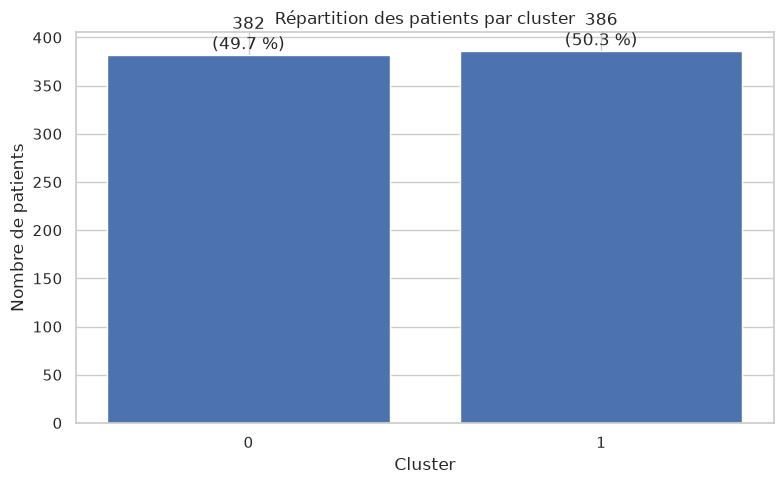

In [46]:
plt.figure(figsize=(8, 5))

plt.bar(
    cluster_distribution.index.astype(str),
    cluster_distribution["count"],
)

plt.xlabel("Cluster")
plt.ylabel("Nombre de patients")
plt.title("Répartition des patients par cluster")

for cluster_id, count in cluster_distribution["count"].items():
    percentage = cluster_distribution.loc[cluster_id, "percentage"]

    plt.text(
        cluster_id,
        count,
        f"{count}\n({percentage:.1f} %)",
        ha="center",
        va="bottom",
    )

plt.tight_layout()
plt.show()

### 21.8 Vérifications finales

In [47]:
assert len(pca_df) == len(df_clustered)

assert (
    pca_df["Cluster"].value_counts().sort_index().to_dict()
    == df_clustered["Cluster"].value_counts().sort_index().to_dict()
)

assert abs(
    total_explained_variance
    - pca.explained_variance_ratio_.sum() * 100
) < 1e-10

print("\n✅ PCA et vérifications terminées.")


✅ PCA et vérifications terminées.


## 22. Interprétation clinique des clusters et création de `risk_category`

Le clustering a permis d'identifier deux profils de patients. Nous allons maintenant interpréter ces profils à partir des caractéristiques cliniques conservées dans `df_clustered`.

### Règle de risque définie par le projet

Le cahier des charges indique qu'un cluster peut être interprété comme **à haut risque** lorsque les moyennes des trois variables suivantes dépassent leurs seuils respectifs :

| Variable                   | Seuil du projet |
| -------------------------- | --------------: |
| `Glucose`                  |           > 126 |
| `BMI`                      |            > 30 |
| `DiabetesPedigreeFunction` |           > 0,5 |

Pour chaque cluster, nous vérifions donc individuellement ces trois conditions.

### Nombre de critères dépassés

Nous construisons également un indicateur `criteres_depasses` :

* `0` : aucun critère dépassé ;
* `1` : un critère dépassé ;
* `2` : deux critères dépassés ;
* `3` : les trois critères dépassés.

Cela permet de résumer simplement le profil de chaque groupe.

### Interprétation

D'après les profils obtenus précédemment :

* **Cluster 0** présente une glycémie moyenne de `103,33`, un BMI moyen de `28,24` et une DPF moyenne de `0,44`. Aucun des trois seuils n'est dépassé.
* **Cluster 1** présente une glycémie moyenne de `139,77`, un BMI moyen de `36,60` et une DPF moyenne de `0,51`. Les trois seuils sont dépassés.

Selon la règle définie dans le projet :

* `Cluster 0` → **Risque Faible**
* `Cluster 1` → **Risque Élevé**

### Important

Cette catégorisation correspond à une **règle d'interprétation du projet** appliquée aux profils issus du clustering. Elle ne constitue pas à elle seule un diagnostic médical individuel.

La colonne `risk_category` sera utilisée dans les étapes suivantes pour rendre les résultats compréhensibles dans l'application métier et pour conserver une correspondance claire entre le cluster et son interprétation.


### 22.1 Seuils définis par le projet

In [48]:
RISK_THRESHOLDS = {
    "Glucose": 126,
    "BMI": 30,
    "DiabetesPedigreeFunction": 0.5,
}

RISK_FEATURES = list(RISK_THRESHOLDS.keys())

print("Seuils de risque définis par le projet :")
display(
    pd.DataFrame(
        {
            "feature": RISK_THRESHOLDS.keys(),
            "threshold": RISK_THRESHOLDS.values(),
            "rule": [">" for _ in RISK_THRESHOLDS],
        }
    )
)

Seuils de risque définis par le projet :


,feature,threshold,rule
0,Glucose,126.0,>
1,BMI,30.0,>
2,DiabetesPedigreeFunction,0.5,>


### 22.2 Calcul des critères dépassés pour chaque cluster

In [49]:
risk_profile = cluster_profiles.copy()

for feature, threshold in RISK_THRESHOLDS.items():
    risk_profile[f"{feature}_threshold_exceeded"] = (
        risk_profile[feature] > threshold
    )

risk_profile["criteres_depasses"] = sum(
    risk_profile[f"{feature}_threshold_exceeded"].astype(int)
    for feature in RISK_THRESHOLDS
)

print("\nAnalyse des seuils par cluster :")
display(
    risk_profile[
        [
            "count",
            "percentage",
            "Glucose",
            "BMI",
            "DiabetesPedigreeFunction",
            "Glucose_threshold_exceeded",
            "BMI_threshold_exceeded",
            "DiabetesPedigreeFunction_threshold_exceeded",
            "criteres_depasses",
        ]
    ].round(3)
)


Analyse des seuils par cluster :


,count,percentage,Glucose,BMI,DiabetesPedigreeFunction,Glucose_threshold_exceeded,BMI_threshold_exceeded,DiabetesPedigreeFunction_threshold_exceeded,criteres_depasses
Cluster,,,,,,,,,
0,382,49.74,103.325,28.243,0.436,False,False,False,0
1,386,50.26,139.769,36.600,0.508,True,True,True,3


### 22.3 Identification automatique du cluster à haut risque

In [ ]:
high_risk_clusters = risk_profile.index[
    (
        (risk_profile["Glucose"] > RISK_THRESHOLDS["Glucose"])
        & (risk_profile["BMI"] > RISK_THRESHOLDS["BMI"])
        & (
            risk_profile["DiabetesPedigreeFunction"]
            > RISK_THRESHOLDS["DiabetesPedigreeFunction"]
        )
    )
].tolist()

low_risk_clusters = [
    cluster
    for cluster in risk_profile.index
    if cluster not in high_risk_clusters
]

print("\nClusters satisfaisant les trois critères de haut risque :")
print(high_risk_clusters)

print("\nAutres clusters :")
print(low_risk_clusters)

assert len(high_risk_clusters) == 1, (
    "Le projet suppose un unique cluster à haut risque, "
    f"mais {len(high_risk_clusters)} clusters satisfont les trois seuils."
)

HIGH_RISK_CLUSTER = high_risk_clusters[0]


Clusters satisfaisant les trois critères de haut risque :
[1]

Autres clusters :
[0]


### 22.4 Création de risk_category

In [51]:
risk_mapping = {
    cluster: (
        "Risque Élevé"
        if cluster == HIGH_RISK_CLUSTER
        else "Risque Faible"
    )
    for cluster in risk_profile.index
}

df_clustered["risk_category"] = (
    df_clustered["Cluster"]
    .map(risk_mapping)
)

assert df_clustered["risk_category"].isna().sum() == 0

print("\nConvention finale :")
for cluster, category in risk_mapping.items():
    print(f"Cluster {cluster} → {category}")



Convention finale :
Cluster 0 → Risque Faible
Cluster 1 → Risque Élevé


### 22.5 Vérification de la correspondance Cluster / Risque

In [52]:
risk_mapping_table = (
    df_clustered[["Cluster", "risk_category"]]
    .drop_duplicates()
    .sort_values("Cluster")
    .reset_index(drop=True)
)

print("\nCorrespondance Cluster / risk_category :")
display(risk_mapping_table)


Correspondance Cluster / risk_category :


,Cluster,risk_category
0,0,Risque Faible
1,1,Risque Élevé


### 22.6 Distribution des catégories de risque

In [53]:
risk_distribution = (
    df_clustered["risk_category"]
    .value_counts()
    .to_frame("count")
)

risk_distribution["percentage"] = (
    risk_distribution["count"]
    / len(df_clustered)
    * 100
)

print("\nDistribution des catégories de risque :")
display(risk_distribution.round(2))


Distribution des catégories de risque :


,count,percentage
risk_category,,
Risque Élevé,386,50.26
Risque Faible,382,49.74


### 22.7 Comparaison des profils par catégorie de risque

In [54]:
risk_profiles = (
    df_clustered
    .groupby("risk_category")[FEATURES]
    .mean()
)

risk_counts = (
    df_clustered["risk_category"]
    .value_counts()
)

risk_profiles.insert(
    0,
    "count",
    risk_counts
)

risk_profiles.insert(
    1,
    "percentage",
    risk_counts
    .div(len(df_clustered))
    .mul(100)
)

print("\nProfil clinique moyen par catégorie de risque :")
display(risk_profiles.round(2))


Profil clinique moyen par catégorie de risque :


,count,percentage,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
risk_category,,,,,,,,,,
Risque Faible,382,49.74,3.37,103.33,67.87,23.37,100.37,28.24,0.44,30.16
Risque Élevé,386,50.26,4.31,139.77,76.79,34.39,204.48,36.60,0.51,36.29


### 22.8 Nombre de patients dépassant chaque seuil

In [55]:
patient_threshold_analysis = pd.DataFrame(index=sorted(RISK_THRESHOLDS))

for feature, threshold in RISK_THRESHOLDS.items():

    patient_threshold_analysis.loc[feature, "threshold"] = threshold

    patient_threshold_analysis.loc[feature, "patients_above"] = (
        df_clustered[feature] > threshold
    ).sum()

    patient_threshold_analysis.loc[feature, "percentage_above"] = (
        df_clustered[feature].gt(threshold).mean() * 100
    )

print("\nPatients dépassant individuellement chaque seuil :")
display(patient_threshold_analysis.round(2))


Patients dépassant individuellement chaque seuil :


,threshold,patients_above,percentage_above
BMI,30.0,475.0,61.85
DiabetesPedigreeFunction,0.5,277.0,36.07
Glucose,126.0,290.0,37.76


### 22.9 Visualisation des variables utilisées pour le risque

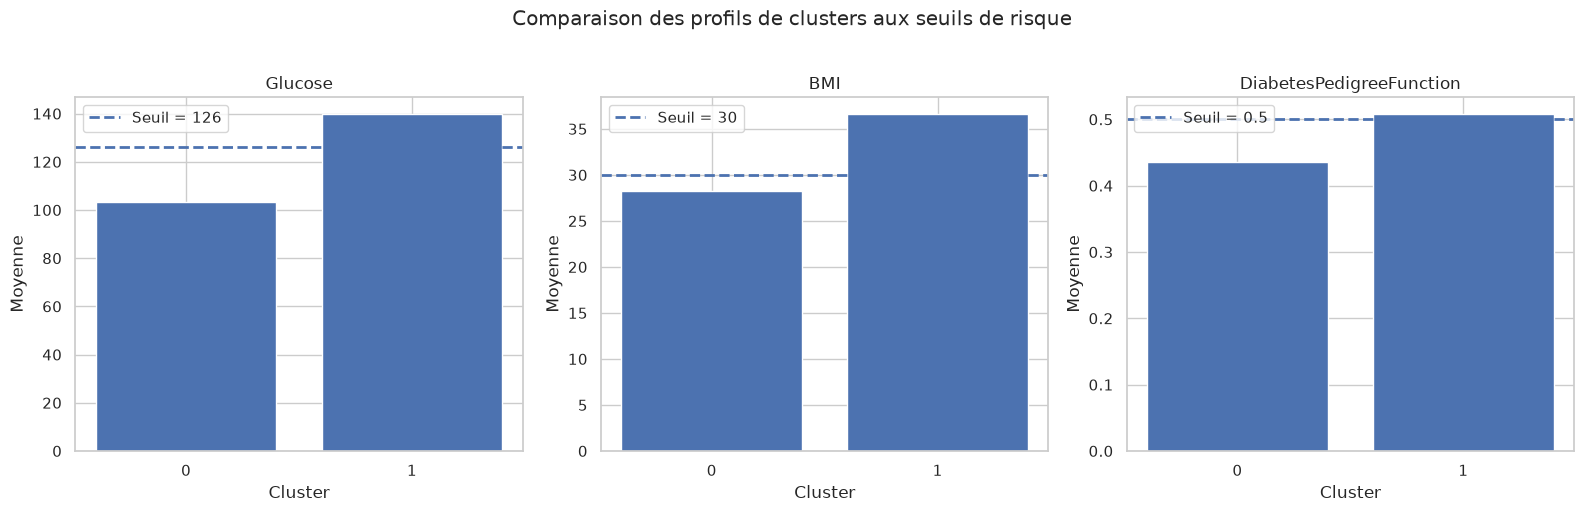

In [56]:
fig, axes = plt.subplots(
    1,
    len(RISK_FEATURES),
    figsize=(16, 5)
)

for ax, feature in zip(axes, RISK_FEATURES):

    means = risk_profile[feature]

    ax.bar(
        means.index.astype(str),
        means.values,
    )

    ax.axhline(
        RISK_THRESHOLDS[feature],
        linestyle="--",
        linewidth=2,
        label=f"Seuil = {RISK_THRESHOLDS[feature]}",
    )

    ax.set_title(feature)
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Moyenne")
    ax.legend()

plt.suptitle(
    "Comparaison des profils de clusters aux seuils de risque",
    y=1.02,
)

plt.tight_layout()
plt.show()

### 22.10 Vérifications finales

In [57]:
assert set(df_clustered["risk_category"].unique()) == {
    "Risque Faible",
    "Risque Élevé",
}

assert (
    df_clustered.loc[
        df_clustered["Cluster"] == HIGH_RISK_CLUSTER,
        "risk_category",
    ]
    == "Risque Élevé"
).all()

print("\n✅ Interprétation clinique et catégorisation terminées.")

print("\nAperçu du dataset enrichi :")
display(df_clustered.head())

print(f"\nShape : {df_clustered.shape}")


✅ Interprétation clinique et catégorisation terminées.

Aperçu du dataset enrichi :


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Cluster,risk_category
0,6.0,148.0,72.0,35.00000,218.922936,33.6,0.627,50.0,1,Risque Élevé
1,1.0,85.0,66.0,29.00000,70.302990,26.6,0.351,31.0,0,Risque Faible
2,8.0,183.0,64.0,21.53261,268.502273,23.3,0.672,32.0,1,Risque Élevé
3,1.0,89.0,66.0,23.00000,94.000000,28.1,0.167,21.0,0,Risque Faible
4,0.0,137.0,40.0,35.00000,168.000000,43.1,2.288,33.0,1,Risque Élevé



Shape : (768, 10)


## 23. Conclusion

Cette étape de clustering avait pour objectif d'identifier des profils homogènes de patients à partir de données cliniques, sans utiliser la variable `Outcome` ni aucune étiquette supervisée.

Plusieurs familles de méthodes ont été étudiées :

* **K-Means** : partitionnement par centroïdes ;
* **GMM** : clustering probabiliste ;
* **Agglomerative Clustering** : approche hiérarchique ;
* **DBSCAN** : clustering fondé sur la densité.

Plusieurs transformations d'échelle ont également été comparées, notamment `StandardScaler`, `RobustScaler`, `MinMaxScaler`, `QuantileTransformer` et `PowerTransformer`.

### Résultats principaux

Les expériences montrent que les patients ne forment pas des groupes naturellement très séparés. Plusieurs indicateurs convergent vers cette conclusion :

* silhouettes relativement faibles ;
* absence de coude très marqué ;
* difficultés de DBSCAN à produire plusieurs groupes équilibrés ;
* stabilité dégradée lorsque le nombre de clusters augmente ;
* différences entre plusieurs modèles concentrées autour d'une zone frontière.

Le dataset semble donc davantage représenter un **continuum de profils métaboliques** qu'une séparation naturelle entre catégories parfaitement distinctes.

Malgré cette limite, une partition en **deux profils** reste pertinente pour l'objectif du projet.

### Sélection des variables

La variance brute n'a pas été utilisée comme unique critère de sélection, car elle dépend fortement des unités de mesure.

L'analyse du pouvoir de séparation (`η²`) a montré que le noyau métabolique composé de :

* `Glucose`
* `BloodPressure`
* `SkinThickness`
* `Insulin`
* `BMI`

permettait d'obtenir une segmentation plus orientée vers les caractéristiques métaboliques et moins dominée par `Age` et `Pregnancies`.

Cette sélection a ensuite été revalidée en testant à nouveau plusieurs scalers et plusieurs valeurs de `k`.

### Modèle final

La configuration finale retenue est :

| Élément                 | Choix final                  |
| ----------------------- | ---------------------------- |
| Algorithme              | **K-Means**                  |
| Scaler                  | **RobustScaler**             |
| Nombre de clusters      | **2**                        |
| Variables de clustering | **5 variables métaboliques** |
| `random_state`          | **42**                       |

Le modèle final produit deux groupes de tailles pratiquement équilibrées :

* **Cluster 0 : 382 patients (49,74 %)**
* **Cluster 1 : 386 patients (50,26 %)**

Les profils moyens sont fortement différenciés sur les variables utilisées pour l'interprétation :

| Variable                 | Cluster 0 | Cluster 1 |
| ------------------------ | --------: | --------: |
| Glucose                  |    103,33 |    139,77 |
| BloodPressure            |     67,87 |     76,79 |
| SkinThickness            |     23,37 |     34,39 |
| Insulin                  |    100,37 |    204,48 |
| BMI                      |     28,24 |     36,60 |
| DiabetesPedigreeFunction |      0,44 |      0,51 |
| Age                      |     30,16 |     36,29 |

### Interprétation du risque

Selon la règle définie dans le cahier des charges :

* **Glucose > 126**
* **BMI > 30**
* **DiabetesPedigreeFunction > 0,5**

le Cluster 0 ne dépasse aucun des trois seuils, tandis que le Cluster 1 dépasse les trois.

La correspondance finale est donc :

```text
Cluster 0 → Risque Faible
Cluster 1 → Risque Élevé
```

La colonne `risk_category` a été ajoutée au dataset afin de fournir une interprétation métier directement exploitable.

### Visualisation PCA

La projection PCA des cinq variables utilisées pour le clustering explique :

* **48,25 %** de la variance avec PC1 ;
* **24,35 %** avec PC2 ;
* soit **72,60 %** avec les deux premières composantes.

Cette représentation fournit donc une visualisation 2D utile de la structure du dataset, mais elle reste une projection : elle ne doit pas être interprétée comme une preuve d'une séparation naturelle parfaite.

### Limites

Le clustering obtenu doit être interprété comme une **segmentation de profils**, et non comme une vérité biologique ou un diagnostic médical.

La silhouette relativement faible montre que la frontière entre les deux profils n'est pas parfaitement nette. Une proportion non négligeable de patients se trouve dans une zone intermédiaire, comme l'ont montré les analyses de stabilité.

De plus, la catégorie `risk_category` repose sur une règle spécifique au projet appliquée aux **moyennes des clusters**. Elle ne constitue pas, à elle seule, une classification médicale individuelle.

### Artefacts produits

Les principaux éléments nécessaires à la suite du projet ont été sauvegardés :

* scaler `RobustScaler` ;
* modèle K-Means ;
* modèle PCA ;
* dataset enrichi avec `Cluster` et `risk_category` ;
* configuration du clustering ;
* rapports des profils et de la variance PCA.

Le dataset enrichi constitue désormais l'entrée de l'étape suivante du projet : la **classification supervisée**, où `Cluster` sera utilisé comme variable cible afin d'apprendre à reproduire la segmentation pour de nouveaux patients.

## Fin du notebook de clustering

Le clustering non supervisé est donc terminé. La prochaine étape consiste à construire et comparer les modèles de classification supervisée à partir de la colonne `Cluster`.
